# Student Depression Analysis and Prediction Using Machine Learning Techniques

**Dataset:** `Student Depression Dataset.csv`  |  **Target variable:** `Depression`  |  **Task:** Binary classification

**Notebook contents**

1. Project Introduction
2. Importing Libraries
3. Dataset Loading and Initial Inspection
4. Data Cleaning and Preprocessing
5. Exploratory Data Analysis (EDA)
6. Feature Selection and Train-Test Split
7. Building Machine Learning Models (7 models)
8. Model Evaluation
9. Model Comparison and Best Model Selection (plus two extra experiments)
10. Feature Importance and Model Interpretation
11. Final Conclusion
12. Research Summary Generation (writes `research_summary.md`)

> **Important:** This is an academic project. The models here are research tools only and must **not** be used as a clinical or diagnostic system.

# Section 1: Project Introduction

### 1.1 What is student depression prediction?

Depression is a common mental-health condition. It affects mood, sleep, concentration, energy and daily functioning. Students are an important group to study because they face academic pressure, financial worries, irregular sleep, and big life changes at the same time.

**Student depression prediction** means using information about a student (for example age, academic pressure, sleep duration, dietary habits and financial stress) to estimate whether that student is likely to be in the "depressed" group of our dataset.

### 1.2 Why can machine learning be used for this problem?

- The dataset contains many features, and the relationship between them and depression is not simple. Machine learning algorithms can learn such patterns automatically from labelled examples.
- Once trained, a model can score new students very quickly.
- Interpretable models and feature-importance tools also help us see **which factors are associated with depression**, which is useful for research.

### 1.3 Problem statement

Given the academic, lifestyle and personal information of a student, can we build a classification model that predicts whether the student belongs to the depressed class (`Depression = 1`) or not (`Depression = 0`), and which factors matter most for that prediction?

### 1.4 Objectives

1. Inspect the dataset and find data-quality problems (missing, invalid and inconsistent values).
2. Clean and preprocess the data without data leakage.
3. Explore the data with visualisations to understand patterns related to depression.
4. Train and compare **seven** classification models.
5. Evaluate the models using Accuracy, Precision, Recall, F1-Score, ROC-AUC and confusion matrices (not accuracy alone).
6. Study the effect of the sensitive feature *"Have you ever had suicidal thoughts?"* with a separate experiment.
7. Find the most influential features and interpret them carefully (association, not causation).

### 1.5 Target variable

`Depression` is a binary variable: `1` = student is in the depressed class, `0` = not in the depressed class. The CSV file does not describe how this label was collected (for example self-report survey or clinical assessment), so we treat it as the "ground truth" provided with the dataset and mention this as a limitation.

### 1.6 Expected outcome

- A clean, reproducible notebook with seven trained models and a fair comparison between them.
- Clear evidence about which features are most associated with depression in this dataset.
- A saved comparison table (`model_comparison.csv`) and a research summary (`research_summary.md`) that can be used later for a research paper.

# Section 2: Importing Libraries

### What we are going to do and why

We import only the libraries that this project really needs:

- **pandas, NumPy** – loading and handling tabular data and numbers.
- **Matplotlib, Seaborn** – visualisation.
- **scikit-learn** – preprocessing (`ColumnTransformer`, `Pipeline`, encoders, scaler), models, cross-validation and evaluation metrics.

We also fix `RANDOM_STATE = 42` once, so every random operation (train-test split, models, cross-validation) gives the same result each time the notebook is run.

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn: data preparation
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

# Scikit-learn: the seven models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Scikit-learn: evaluation and interpretation
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, confusion_matrix)
from sklearn.inspection import permutation_importance

import sklearn

# One random seed for the whole notebook (reproducibility)
RANDOM_STATE = 42

# A clean, readable plotting style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)
print("matplotlib:", plt.matplotlib.__version__, "| seaborn:", sns.__version__)

pandas: 2.2.3 | numpy: 2.2.4 | scikit-learn: 1.8.0
matplotlib: 3.10.1 | seaborn: 0.13.2


### Observation

The libraries imported correctly and the printed versions are the ones used for this run. Writing the versions down is good practice for reproducibility; they are also listed in `requirements.txt`.

# Section 3: Dataset Loading and Initial Inspection

### 3.1 Loading the dataset

We load the CSV file with pandas. The file must be in the same folder as this notebook. The CSV does not contain any information about where the data was collected, so the **source of the dataset is not documented in the file**. We keep a note of this for the research paper and do not invent a source.

In [2]:
# Name of the dataset file (kept in the same folder as the notebook)
DATA_FILE = "Student Depression Dataset.csv"

# Load the CSV file into a pandas DataFrame
df = pd.read_csv(DATA_FILE)

print("Dataset loaded successfully.")

Dataset loaded successfully.


### 3.2 First five rows

Looking at the first rows gives a quick feeling for the columns and the type of values stored in each of them.

In [3]:
df.head()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,2,Male,33.0,Visakhapatnam,Student,5.0,0.0,8.97,2.0,0.0,5-6 hours,Healthy,B.Pharm,Yes,3.0,1.0,No,1
1,8,Female,24.0,Bangalore,Student,2.0,0.0,5.90,5.0,0.0,5-6 hours,Moderate,BSc,No,3.0,2.0,Yes,0
2,26,Male,31.0,Srinagar,Student,3.0,0.0,7.03,5.0,0.0,Less than 5 hours,Healthy,BA,No,9.0,1.0,Yes,0
3,30,Female,28.0,Varanasi,Student,3.0,0.0,5.59,2.0,0.0,7-8 hours,Moderate,BCA,Yes,4.0,5.0,Yes,1
4,32,Female,25.0,Jaipur,Student,4.0,0.0,8.13,3.0,0.0,5-6 hours,Moderate,M.Tech,Yes,1.0,1.0,No,0


### 3.3 Last five rows

Checking the last rows helps us confirm that the file was read completely and the data does not look different at the end.

In [4]:
df.tail()

,id,Gender,Age,City,Profession,Academic Pressure,Work Pressure,CGPA,Study Satisfaction,Job Satisfaction,Sleep Duration,Dietary Habits,Degree,Have you ever had suicidal thoughts ?,Work/Study Hours,Financial Stress,Family History of Mental Illness,Depression
27896,140685,Female,27.0,Surat,Student,5.0,0.0,5.75,5.0,0.0,5-6 hours,Unhealthy,Class 12,Yes,7.0,1.0,Yes,0
27897,140686,Male,27.0,Ludhiana,Student,2.0,0.0,9.40,3.0,0.0,Less than 5 hours,Healthy,MSc,No,0.0,3.0,Yes,0
27898,140689,Male,31.0,Faridabad,Student,3.0,0.0,6.61,4.0,0.0,5-6 hours,Unhealthy,MD,No,12.0,2.0,No,0
27899,140690,Female,18.0,Ludhiana,Student,5.0,0.0,6.88,2.0,0.0,Less than 5 hours,Healthy,Class 12,Yes,10.0,5.0,No,1
27900,140699,Male,27.0,Patna,Student,4.0,0.0,9.24,1.0,0.0,Less than 5 hours,Healthy,BCA,Yes,2.0,3.0,Yes,1


### 3.4 Dataset dimensions and column names

We check how many rows (students) and columns (variables) the dataset has, and the exact column names. Exact names matter because one column name contains a space before the question mark (`Have you ever had suicidal thoughts ?`).

In [5]:
number_of_rows, number_of_columns = df.shape
print(f"Number of rows (students): {number_of_rows}")
print(f"Number of columns: {number_of_columns}")
print()
print("Column names:")
for column_name in df.columns:
    print(f" - {repr(column_name)}")

Number of rows (students): 27901
Number of columns: 18

Column names:
 - 'id'
 - 'Gender'
 - 'Age'
 - 'City'
 - 'Profession'
 - 'Academic Pressure'
 - 'Work Pressure'
 - 'CGPA'
 - 'Study Satisfaction'
 - 'Job Satisfaction'
 - 'Sleep Duration'
 - 'Dietary Habits'
 - 'Degree'
 - 'Have you ever had suicidal thoughts ?'
 - 'Work/Study Hours'
 - 'Financial Stress'
 - 'Family History of Mental Illness'
 - 'Depression'


### Observation

The dataset has the dimensions printed above. Using `repr()` shows the column names exactly as stored, including the unusual space in `Have you ever had suicidal thoughts ?`. We will rename this column to a simpler name during cleaning.

### 3.5 Data types and memory information

`df.info()` shows the data type of each column and the number of non-null values. A column that should be numeric but is stored as text (or the opposite) is a sign of a data-quality problem.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27901 entries, 0 to 27900
Data columns (total 18 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   id                                     27901 non-null  int64  
 1   Gender                                 27901 non-null  object 
 2   Age                                    27901 non-null  float64
 3   City                                   27901 non-null  object 
 4   Profession                             27901 non-null  object 
 5   Academic Pressure                      27901 non-null  float64
 6   Work Pressure                          27901 non-null  float64
 7   CGPA                                   27901 non-null  float64
 8   Study Satisfaction                     27901 non-null  float64
 9   Job Satisfaction                       27901 non-null  float64
 10  Sleep Duration                         27901 non-null  object 
 11  Di

### Observation

Numerical columns are stored as `int64`/`float64`, and categorical columns are stored as text (strings). Almost every column shows the full count of non-null values; only `Financial Stress` has a few missing entries (we confirm this in Section 3.7).

### 3.6 Statistical summary

The statistical summary of the numerical columns (count, mean, standard deviation, min, quartiles, max) helps us detect impossible values, constant columns and possible outliers.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,27901.0,70442.149421,40641.175216,2.0,35039.00,70684.00,105818.00,140699.0
Age,27901.0,25.822300,4.905687,18.0,21.00,25.00,30.00,59.0
Academic Pressure,27901.0,3.141214,1.381465,0.0,2.00,3.00,4.00,5.0
Work Pressure,27901.0,0.000430,0.043992,0.0,0.00,0.00,0.00,5.0
CGPA,27901.0,7.656104,1.470707,0.0,6.29,7.77,8.92,10.0
Study Satisfaction,27901.0,2.943837,1.361148,0.0,2.00,3.00,4.00,5.0
Job Satisfaction,27901.0,0.000681,0.044394,0.0,0.00,0.00,0.00,4.0
Work/Study Hours,27901.0,7.156984,3.707642,0.0,4.00,8.00,10.00,12.0
Financial Stress,27898.0,3.139867,1.437347,1.0,2.00,3.00,4.00,5.0
Depression,27901.0,0.585499,0.492645,0.0,0.00,1.00,1.00,1.0


### Observation

Important points from the summary:

- `Work Pressure` and `Job Satisfaction` have a mean of almost `0` and a 75th percentile of `0`. They are therefore almost constant. This is expected because nearly all people in this dataset are students, not employees.
- `Academic Pressure`, `Study Satisfaction` and `Financial Stress` are rating scales. `Academic Pressure` and `Study Satisfaction` have a minimum of `0`, even though the main scale appears to be `1–5`. We will check this carefully.
- `CGPA` has a minimum of `0`, which is suspicious for a 10-point CGPA scale.
- `Age` ranges up to 59, which is far above the typical student age. We will check how many such students exist.

### 3.7 Missing values

Missing values can reduce model quality or even stop some algorithms from running. We count them in every column.

In [8]:
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df) * 100).round(4)

missing_table = pd.DataFrame({"Missing Values": missing_values,
                              "Missing Percentage (%)": missing_percentage})
missing_table

,Missing Values,Missing Percentage (%)
id,0,0.0000
Gender,0,0.0000
Age,0,0.0000
City,0,0.0000
Profession,0,0.0000
Academic Pressure,0,0.0000
Work Pressure,0,0.0000
CGPA,0,0.0000
Study Satisfaction,0,0.0000
Job Satisfaction,0,0.0000


### Observation

Only `Financial Stress` contains missing values (3 rows, which is a very small part of the data). We will not delete these rows. Instead, we will fill the missing values with the **median** of the training data inside the preprocessing pipeline (Section 4), which avoids data leakage.

### 3.8 Duplicate records

Duplicate rows can make the model see the same student twice and can leak information between the training and test sets. Since `id` is unique by definition, we check duplicates both with and without `id`.

In [9]:
duplicates_with_id = df.duplicated().sum()
duplicates_without_id = df.drop(columns=["id"]).duplicated().sum()

print("Duplicate rows (all columns):", duplicates_with_id)
print("Duplicate rows (ignoring the id column):", duplicates_without_id)
print("Is id unique for every row? ->", df["id"].is_unique)

Duplicate rows (all columns): 0
Duplicate rows (ignoring the id column): 0
Is id unique for every row? -> True


### Observation

There are no duplicate rows, even after ignoring `id`. So no records need to be removed because of duplication.

### 3.9 Separating numerical and categorical columns

We split the columns by data type. This gives us the list of features that need scaling (numerical) and the list that needs encoding (categorical).

In [10]:
# Columns with numbers
numerical_columns = df.select_dtypes(include="number").columns.tolist()

# All remaining columns hold text (categorical data)
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical columns:")
print(numerical_columns)
print()
print("Categorical columns:")
print(categorical_columns)

Numerical columns:
['id', 'Age', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Work/Study Hours', 'Financial Stress', 'Depression']

Categorical columns:
['Gender', 'City', 'Profession', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Have you ever had suicidal thoughts ?', 'Family History of Mental Illness']


### Observation

`id` and `Depression` are numeric but are **not** ordinary numerical features: `id` is only an identifier and `Depression` is our target. Several rating columns (`Academic Pressure`, `Study Satisfaction`, `Financial Stress`) are stored as numbers, but they are really ordered scores from 1 to 5.

### 3.10 Unique values in the categorical columns

For each categorical column we look at the number of unique values and the most frequent ones. This is the best way to find typing mistakes, rare categories and values that do not belong in the column.

In [11]:
for column_name in categorical_columns:
    print(f"=== {column_name}  (unique values: {df[column_name].nunique()}) ===")
    # Show at most the 12 most frequent values to keep the output readable
    print(df[column_name].value_counts().head(12).to_string())
    print()

=== Gender  (unique values: 2) ===
Gender
Male      15547
Female    12354

=== City  (unique values: 52) ===
City
Kalyan         1570
Srinagar       1372
Hyderabad      1340
Vasai-Virar    1290
Lucknow        1155
Thane          1139
Ludhiana       1111
Agra           1094
Surat          1078
Kolkata        1066
Jaipur         1036
Patna          1007

=== Profession  (unique values: 14) ===
Profession
Student                   27870
Architect                     8
Teacher                       6
Digital Marketer              3
Chef                          2
Content Writer                2
Pharmacist                    2
Doctor                        2
UX/UI Designer                1
Civil Engineer                1
Manager                       1
Educational Consultant        1

=== Sleep Duration  (unique values: 5) ===
Sleep Duration
Less than 5 hours    8310
7-8 hours            7346
5-6 hours            6183
More than 8 hours    6044
Others                 18

=== Dietary Habits  

### Observation

Important data-quality findings:

- `Gender`, `Have you ever had suicidal thoughts ?` and `Family History of Mental Illness` have only two values each, so they are clean binary columns.
- `Sleep Duration` and `Dietary Habits` contain a value called `Others`, which is not a real category of sleep or diet. It has very few rows (18 and 12).
- `Profession` is `Student` for almost every row, so it carries almost no information.
- `City` has 52 unique values, which is more than expected. We inspect it further in Section 4 because the 12 most frequent values shown above are real cities, but the rare values may not be.
- `Degree` has many categories, some of them very rare (including `Others`).

# Section 4: Data Cleaning and Preprocessing

In this section we decide what is wrong with the data and how to treat it. We follow a simple rule:

> **Fixes that depend only on a fixed rule** (for example "a CGPA of 0 is impossible") are done now on the whole dataset.
> **Fixes that depend on data statistics** (median, most frequent value, scaling, encoding) are done later **inside a Pipeline that is fitted on training data only**, to avoid data leakage.

We keep a short list called `preprocessing_decisions` so that every decision is available later for the research paper.

In [12]:
# A list that records every preprocessing decision (used later in the research summary)
preprocessing_decisions = []

# Work on a copy so the original DataFrame is never modified
df_clean = df.copy()

### 4.1 Renaming an awkward column name

The column `Have you ever had suicidal thoughts ?` is long and has a space before the question mark. We rename it to `Suicidal Thoughts` for easier coding. The values (`Yes` / `No`) are not changed.

In [13]:
df_clean = df_clean.rename(columns={"Have you ever had suicidal thoughts ?": "Suicidal Thoughts"})

preprocessing_decisions.append(
    "Renamed 'Have you ever had suicidal thoughts ?' to 'Suicidal Thoughts' (values unchanged).")
print(df_clean.columns.tolist())

['id', 'Gender', 'Age', 'City', 'Profession', 'Academic Pressure', 'Work Pressure', 'CGPA', 'Study Satisfaction', 'Job Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Suicidal Thoughts', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness', 'Depression']


### 4.2 Identifying invalid or inconsistent values

We now check each rating column and the categorical columns for values that do not make sense. The code below counts:

- ratings of `0` in columns whose valid scale is 1–5,
- a CGPA of `0`,
- the placeholder value `Others` in `Sleep Duration` and `Dietary Habits`.

In [14]:
print("Values of the rating columns (value -> number of students):")
for rating_column in ["Academic Pressure", "Study Satisfaction", "Financial Stress"]:
    print(f"\n{rating_column}:")
    print(df_clean[rating_column].value_counts(dropna=False).sort_index().to_string())

print("\nStudents with CGPA = 0:", (df_clean["CGPA"] == 0).sum())
print("Sleep Duration == 'Others':", (df_clean["Sleep Duration"] == "Others").sum())
print("Dietary Habits == 'Others':", (df_clean["Dietary Habits"] == "Others").sum())

Values of the rating columns (value -> number of students):

Academic Pressure:
Academic Pressure
0.0       9
1.0    4801
2.0    4178
3.0    7462
4.0    5155
5.0    6296

Study Satisfaction:
Study Satisfaction
0.0      10
1.0    5451
2.0    5838
3.0    5821
4.0    6359
5.0    4422

Financial Stress:
Financial Stress
1.0    5121
2.0    5061
3.0    5226
4.0    5775
5.0    6715
NaN       3

Students with CGPA = 0: 9
Sleep Duration == 'Others': 18
Dietary Habits == 'Others': 12


### Observation

- `Academic Pressure` has 9 rows with `0` and `Study Satisfaction` has 10 rows with `0`, although every other row uses the scale 1–5. A `0` is therefore outside the valid scale.
- 9 rows have `CGPA = 0`. A student with a CGPA of exactly 0 is very unlikely, so these values are most likely missing or wrongly entered.
- `Sleep Duration = Others` (18 rows) and `Dietary Habits = Others` (12 rows) do not tell us anything about sleep or diet.

**Decision:** we do **not** delete these students (they are only a tiny part of the data and their other columns are valid). We convert the invalid entries to missing values (`NaN`). They will then be filled by the imputer inside the pipeline using training-data statistics.

In [15]:
# Convert invalid values to NaN (a fixed rule, so no leakage)
df_clean.loc[df_clean["Academic Pressure"] == 0, "Academic Pressure"] = np.nan
df_clean.loc[df_clean["Study Satisfaction"] == 0, "Study Satisfaction"] = np.nan
df_clean.loc[df_clean["CGPA"] == 0, "CGPA"] = np.nan
df_clean.loc[df_clean["Sleep Duration"] == "Others", "Sleep Duration"] = np.nan
df_clean.loc[df_clean["Dietary Habits"] == "Others", "Dietary Habits"] = np.nan

preprocessing_decisions.append(
    "Converted impossible values to missing: Academic Pressure = 0 (9 rows), Study Satisfaction = 0 (10 rows), "
    "CGPA = 0 (9 rows), Sleep Duration = 'Others' (18 rows), Dietary Habits = 'Others' (12 rows). No rows were deleted.")

# Check the result: missing values after this step
df_clean.isnull().sum()[lambda counts: counts > 0]

Academic Pressure      9
CGPA                   9
Study Satisfaction    10
Sleep Duration        18
Dietary Habits        12
Financial Stress       3
dtype: int64

### Observation

The columns listed above now contain missing values that came from invalid entries, plus the 3 original missing values in `Financial Stress`. All of them will be imputed inside the pipeline: **median** for numerical and rating columns, **most frequent value** for categorical columns.

### 4.3 Checking the unusual values in `City`

`City` has 52 unique values. Real cities should each have hundreds of students, so we list the rare values to see whether they are genuine cities.

In [16]:
city_counts = df_clean["City"].value_counts()

print("Number of unique City values:", len(city_counts))
print("Cities with at least 100 students:", (city_counts >= 100).sum())
print("Cities with fewer than 100 students:", (city_counts < 100).sum())
print("Students in those rare-city rows:", city_counts[city_counts < 100].sum())
print()
print("Rare City values:")
print(city_counts[city_counts < 100].to_string())

Number of unique City values: 52
Cities with at least 100 students: 30
Cities with fewer than 100 students: 22
Students in those rare-city rows: 26

Rare City values:
City
Saanvi                2
Bhavna                2
City                  2
Harsha                2
Less Delhi            1
M.Tech                1
3.0                   1
Less than 5 Kalyan    1
Mira                  1
Vaanya                1
Gaurav                1
Harsh                 1
Reyansh               1
Kibara                1
Rashi                 1
ME                    1
M.Com                 1
Nalyan                1
Mihir                 1
Nalini                1
Nandini               1
Khaziabad             1


### Observation

There are 30 real-looking cities with hundreds of students each, and 22 rare values with only 1–2 students each (26 students in total). Many of these rare values are **not cities at all**: they look like person names (e.g. `Saanvi`, `Reyansh`), degrees (`M.Tech`, `ME`, `M.Com`), numbers (`3.0`), the word `City`, or spelling mistakes (`Khaziabad`, `Nalyan`). These are shifted or mistyped entries.

**Decision:** we keep these rows (only 26 students in total). In the pipeline the `OneHotEncoder` will merge every category with fewer than 100 training students into one shared "infrequent" group. The rule is learned from training data only, and the invalid city names end up in that group instead of creating dozens of useless columns.

### 4.4 Checking `Profession`, `Work Pressure` and `Job Satisfaction`

We check how much information these three columns really contain.

In [17]:
print("Profession values:")
print(df_clean["Profession"].value_counts().to_string())
print()
print("Share of students: %.2f%%" % (100 * (df_clean["Profession"] == "Student").mean()))
print()
print("Work Pressure  -> share of rows equal to 0: %.3f%%" % (100 * (df_clean["Work Pressure"] == 0).mean()))
print("Job Satisfaction -> share of rows equal to 0: %.3f%%" % (100 * (df_clean["Job Satisfaction"] == 0).mean()))

Profession values:
Profession
Student                   27870
Architect                     8
Teacher                       6
Digital Marketer              3
Chef                          2
Content Writer                2
Pharmacist                    2
Doctor                        2
UX/UI Designer                1
Civil Engineer                1
Manager                       1
Educational Consultant        1
Lawyer                        1
Entrepreneur                  1

Share of students: 99.89%

Work Pressure  -> share of rows equal to 0: 99.989%
Job Satisfaction -> share of rows equal to 0: 99.971%


### Observation

- 99.9% of the rows have `Profession = Student` (only 31 rows are something else).
- 99.99% of the rows have `Work Pressure = 0` and 99.97% have `Job Satisfaction = 0`.

A column that has the same value for almost every row cannot help a model separate depressed from non-depressed students. These three columns describe employment, which does not apply to this student population. **Decision:** drop `Profession`, `Work Pressure` and `Job Satisfaction`, and keep all rows.

### 4.5 Checking outliers

We use the IQR rule (values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR) on the continuous columns to count outliers. We only *count* them first, and then decide what to do.

In [18]:
continuous_columns = ["Age", "CGPA", "Work/Study Hours"]
outlier_rows = []

for column_name in continuous_columns:
    q1 = df_clean[column_name].quantile(0.25)
    q3 = df_clean[column_name].quantile(0.75)
    iqr = q3 - q1
    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr
    outlier_count = ((df_clean[column_name] < lower_limit) | (df_clean[column_name] > upper_limit)).sum()
    outlier_rows.append([column_name, lower_limit, upper_limit, outlier_count])

outlier_table = pd.DataFrame(outlier_rows, columns=["Column", "Lower Limit", "Upper Limit", "Outlier Count"])
outlier_table

,Column,Lower Limit,Upper Limit,Outlier Count
0,Age,7.500,43.500,12
1,CGPA,2.345,12.865,0
2,Work/Study Hours,-5.000,19.000,0


### Observation

Only `Age` has outliers by the IQR rule: **12 students** are older than the upper limit of 43.5 years (the oldest is 59). `CGPA` has none (the 9 impossible zeros were already converted to missing values in Section 4.2) and `Work/Study Hours` has none, since its values range from 0 to 12.

**Decision:** we keep these records. A student aged 45 or 59 is unusual but still possible, so they are valid observations. We also do not remove them because the models we use (trees, boosting, scaled linear models and SVM) are not badly harmed by a handful of extreme values.

### 4.6 Removing irrelevant columns and preparing the features

Columns removed and the reason:

| Column | Reason |
|---|---|
| `id` | Only a row identifier. Using it as a feature would let a model learn row order, not real patterns. |
| `Profession` | Almost constant (99.9% `Student`). |
| `Work Pressure` | Almost constant (99.99% zeros). |
| `Job Satisfaction` | Almost constant (99.97% zeros). |

All other columns are kept. We then separate the full feature table `X` and the target `y` (`Depression`).

In [19]:
columns_to_drop = ["id", "Profession", "Work Pressure", "Job Satisfaction"]

# Target variable
y = df_clean["Depression"]

# Feature table: everything except the target and the dropped columns
X = df_clean.drop(columns=columns_to_drop + ["Depression"])

preprocessing_decisions.append(
    "Dropped id (identifier), Profession (99.9% 'Student'), Work Pressure (99.99% zero) and Job Satisfaction (99.97% zero).")

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Feature columns:", X.columns.tolist())

Shape of X: (27901, 13)
Shape of y: (27901,)
Feature columns: ['Gender', 'Age', 'City', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Suicidal Thoughts', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness']


### Observation

We now have 13 candidate features. All rows are still present (27,901 students).

### 4.7 Deciding how every feature will be encoded

Each feature type needs a suitable treatment:

| Feature group | Columns | Treatment (inside the pipeline) |
|---|---|---|
| Numerical and rating scores | `Age`, `Academic Pressure`, `CGPA`, `Study Satisfaction`, `Work/Study Hours`, `Financial Stress` | Median imputation. Standard scaling only for models that need it (Logistic Regression, KNN, SVM). The 1–5 rating scores are ordered and equally spaced, so we treat them as numbers. |
| Binary categorical | `Gender`, `Suicidal Thoughts`, `Family History of Mental Illness` | Most-frequent imputation, then One-Hot Encoding with `drop="if_binary"` (one 0/1 column each). |
| Ordinal categorical | `Sleep Duration`, `Dietary Habits` | Most-frequent imputation, then **Ordinal Encoding** with a fixed order, because the order is meaningful: sleep from "Less than 5 hours" to "More than 8 hours", and diet from "Unhealthy" to "Healthy". |
| Nominal categorical | `City`, `Degree` | One-Hot Encoding. Rare categories (fewer than 100 training students) are grouped together. Categories unseen during training are also sent to that group. |

The code below stores these lists and defines a function that builds the preprocessing step. Models that depend on distances or on a common feature scale (Logistic Regression, KNN, SVM) get `scale=True`. Tree-based models and Naive Bayes do not need scaling, so they get `scale=False`.

In [20]:
# Feature groups
numeric_columns = ["Age", "Academic Pressure", "CGPA", "Study Satisfaction", "Work/Study Hours", "Financial Stress"]
binary_columns = ["Gender", "Suicidal Thoughts", "Family History of Mental Illness"]
ordinal_columns = ["Sleep Duration", "Dietary Habits"]
nominal_columns = ["City", "Degree"]

# Meaningful order of the ordinal categories (lowest to highest)
sleep_order = ["Less than 5 hours", "5-6 hours", "7-8 hours", "More than 8 hours"]
diet_order = ["Unhealthy", "Moderate", "Healthy"]


def make_preprocessor(binary_cols, scale):
    # Builds the preprocessing step. Nothing is fitted here; fitting happens inside the pipeline
    # when we call .fit() on the TRAINING data only.
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    ordinal_steps = [("imputer", SimpleImputer(strategy="most_frequent")),
                     ("encoder", OrdinalEncoder(categories=[sleep_order, diet_order]))]
    if scale:
        numeric_steps.append(("scaler", StandardScaler()))
        ordinal_steps.append(("scaler", StandardScaler()))

    binary_steps = [("imputer", SimpleImputer(strategy="most_frequent")),
                    ("encoder", OneHotEncoder(drop="if_binary", sparse_output=False))]

    nominal_encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100,
                                    sparse_output=False)

    return ColumnTransformer(transformers=[
        ("numeric", Pipeline(numeric_steps), numeric_columns),
        ("binary", Pipeline(binary_steps), binary_cols),
        ("ordinal", Pipeline(ordinal_steps), ordinal_columns),
        ("nominal", nominal_encoder, nominal_columns),
    ])


preprocessing_decisions.append(
    "Numeric/rating columns: median imputation (+ StandardScaler for LR, KNN, SVM). Binary columns: one-hot with drop='if_binary'. "
    "Sleep Duration and Dietary Habits: most-frequent imputation + OrdinalEncoder with a fixed meaningful order. "
    "City and Degree: one-hot encoding with categories below 100 training rows grouped as 'infrequent'. "
    "All fitting happens inside sklearn Pipelines on training data only.")
print("Preprocessing function defined.")

Preprocessing function defined.


### Observation

Nothing has been fitted yet, we have only described *how* the data will be processed. In Section 6 the split is made first, and in Section 7 the `Pipeline.fit()` call learns the medians, categories and scaling values from the **training set only**. The test set is only transformed with those learned values, so no information from the test set leaks into training.

# Section 5: Exploratory Data Analysis (EDA)

EDA helps us understand the data before modelling. We use `df_clean` (invalid values are `NaN`, which the plots simply ignore). Plots that show the **depression rate** use the mean of the 0/1 target, so a bar at 0.60 means 60% of the students in that group are in the depressed class.

> EDA only shows **associations**, not causes.

First we define two small helper functions to avoid repeating the same plotting code.

In [21]:
# Colours used throughout the notebook
colour_main = "#4C78A8"
colour_depressed = "#E45756"
colour_not_depressed = "#72B7B2"


def tidy_tick_labels(axis):
    # Show rating values such as 3.0 as 3 (purely cosmetic); text labels are left unchanged
    tidy_labels = []
    for tick in axis.get_xticklabels():
        text = tick.get_text()
        try:
            text = str(int(float(text)))
        except ValueError:
            pass
        tidy_labels.append(text)
    axis.set_xticks(range(len(tidy_labels)))
    axis.set_xticklabels(tidy_labels)


def plot_distribution_and_depression_rate(column_name, order=None, x_label=None):
    # Left: how many students in each category. Right: share of depressed students in each category.
    label = x_label if x_label else column_name
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    sns.countplot(data=df_clean, x=column_name, order=order, color=colour_main, ax=axes[0])
    axes[0].set_title(f"Distribution of {label}")
    axes[0].set_xlabel(label)
    axes[0].set_ylabel("Number of students")
    axes[0].bar_label(axes[0].containers[0], fontsize=9)

    sns.barplot(data=df_clean, x=column_name, y="Depression", order=order, errorbar=None,
                color=colour_depressed, ax=axes[1])
    axes[1].set_title(f"Depression Rate by {label}")
    axes[1].set_xlabel(label)
    axes[1].set_ylabel("Proportion of students with depression")
    axes[1].set_ylim(0, 1)
    axes[1].bar_label(axes[1].containers[0], fmt="%.2f", fontsize=9)

    for axis in axes:
        tidy_tick_labels(axis)
    plt.tight_layout()
    plt.show()


def depression_rate_table(column_name):
    # Small table with the number of students and the depression rate for each category
    table = df_clean.groupby(column_name)["Depression"].agg(Students="count", Depression_Rate="mean").round(3)
    return table


print("Helper functions defined.")

Helper functions defined.


### 5.1 Depression distribution (target variable)

We first check how balanced the two classes are. If one class were very small, accuracy would become a misleading metric.

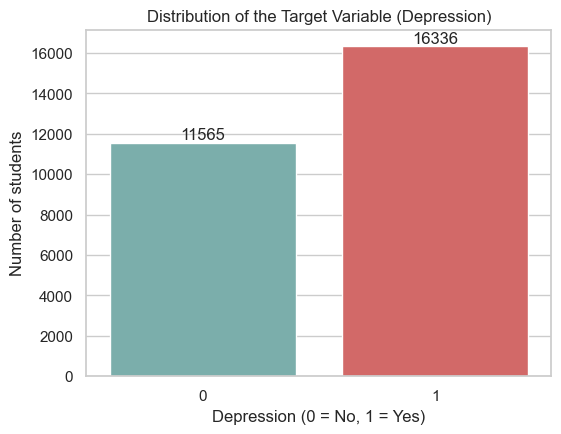

Depression
1    0.5855
0    0.4145
Name: Share of students, dtype: float64


In [22]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(data=df_clean, x="Depression", hue="Depression",
              palette=[colour_not_depressed, colour_depressed], legend=False, ax=ax)
ax.set_title("Distribution of the Target Variable (Depression)")
ax.set_xlabel("Depression (0 = No, 1 = Yes)")
ax.set_ylabel("Number of students")
ax.bar_label(ax.containers[0])
ax.bar_label(ax.containers[1])
plt.show()

print(df_clean["Depression"].value_counts(normalize=True).round(4).rename("Share of students"))

### Observation

About **58.5%** of the students are in the depressed class (`1`) and **41.5%** are not (`0`). The classes are moderately imbalanced, but not severely. A model that always predicts "depressed" would already reach about 58.5% accuracy, so we must look at precision, recall, F1 and ROC-AUC and not at accuracy alone. We also use a **stratified** split so both classes keep the same proportion in the training and test sets.

### 5.2 Gender distribution and depression

We check how many male and female students are present and whether the depression rate differs between them.

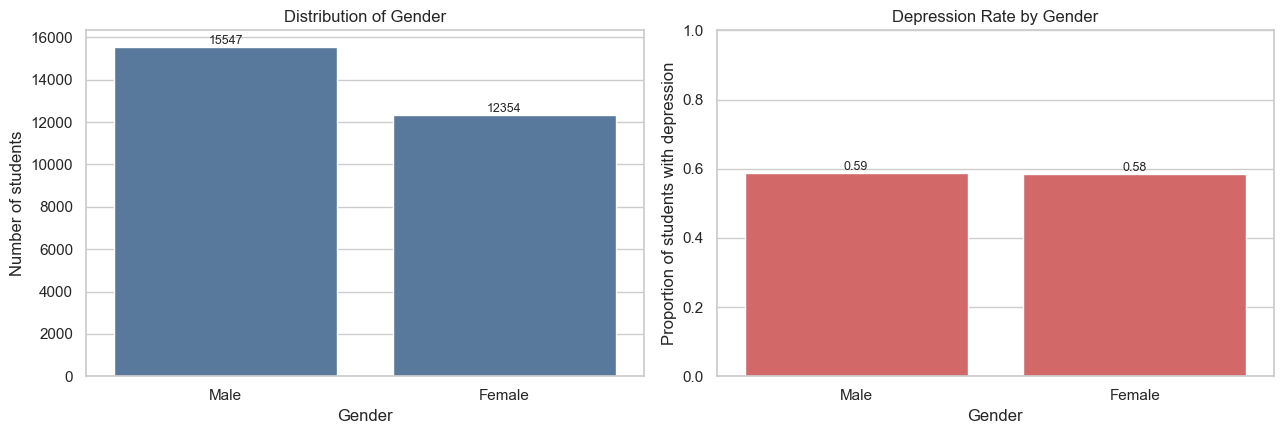

,Students,Depression_Rate
Gender,,
Female,12354,0.585
Male,15547,0.586


In [23]:
plot_distribution_and_depression_rate("Gender")
depression_rate_table("Gender")

### Observation

The dataset has more male students (about 55.7%) than female students (about 44.3%). The depression rate is almost the same for both genders (about 58.6% for males and 58.5% for females), so **gender shows almost no association with depression in this dataset**.

### 5.3 Age distribution and depression

Age is continuous, so we use a histogram for its distribution and a box plot to compare the ages of depressed and non-depressed students.

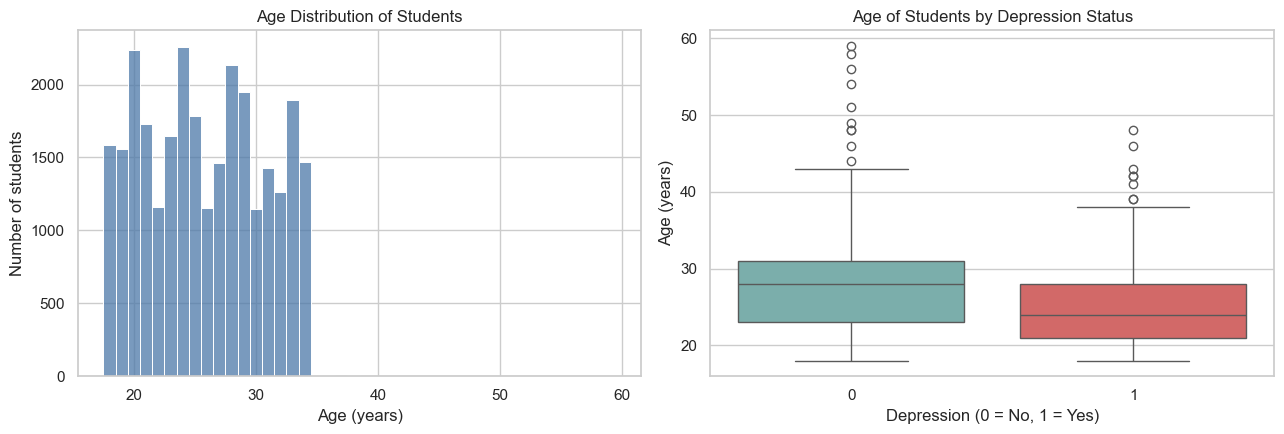

       Students  Depression_Rate
Age                             
18-22      8270            0.697
23-26      6842            0.629
27-30      6690            0.564
31+        6099            0.409

Mean age by depression status:
Depression
0    27.14
1    24.89
Name: Age, dtype: float64


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=df_clean, x="Age", discrete=True, color=colour_main, ax=axes[0])   # one bar per whole year
axes[0].set_title("Age Distribution of Students")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of students")

sns.boxplot(data=df_clean, x="Depression", y="Age", hue="Depression",
            palette=[colour_not_depressed, colour_depressed], legend=False, ax=axes[1])
axes[1].set_title("Age of Students by Depression Status")
axes[1].set_xlabel("Depression (0 = No, 1 = Yes)")
axes[1].set_ylabel("Age (years)")

plt.tight_layout()
plt.show()

# Depression rate for age groups
age_groups = pd.cut(df_clean["Age"], bins=[17, 22, 26, 30, 60], labels=["18-22", "23-26", "27-30", "31+"])
print(df_clean.groupby(age_groups, observed=True)["Depression"].agg(Students="count", Depression_Rate="mean").round(3))
print("\nMean age by depression status:")
print(df_clean.groupby("Depression")["Age"].mean().round(2))

### Observation

Almost all students (99.8%) are between 18 and 34 years old. Only 49 students are older, up to 59, so the right tail of the histogram is barely visible (the box plot shows these older students as outliers). Depressed students are **younger on average** (about 24.9 years) than non-depressed students (about 27.1 years). The depression rate falls steadily with age: about 70% in the 18–22 group down to about 41% for students older than 30.

### 5.4 Academic Pressure distribution and depression

Academic Pressure is a 1–5 rating. We expect higher pressure to be related to a higher depression rate.

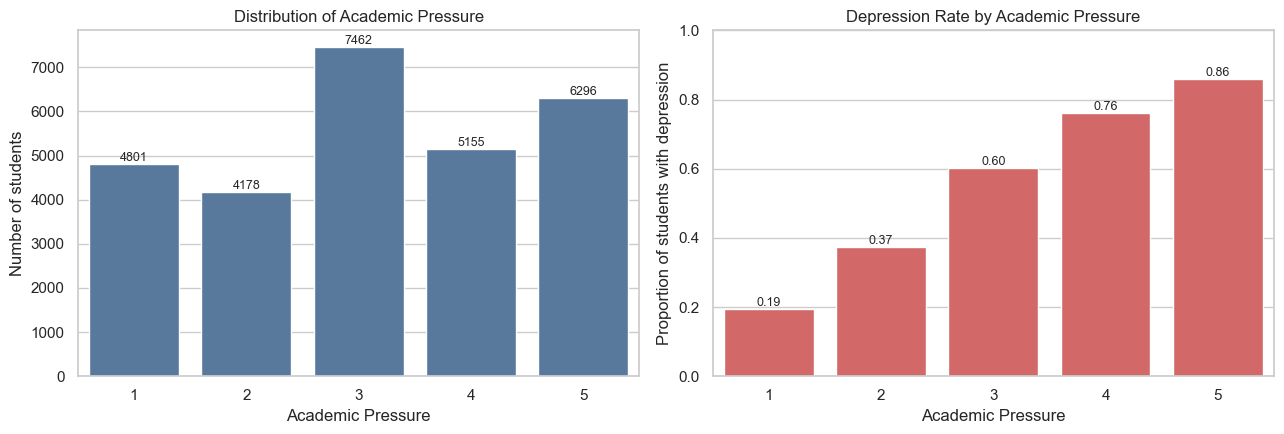

In [25]:
plot_distribution_and_depression_rate("Academic Pressure", order=[1.0, 2.0, 3.0, 4.0, 5.0])

### Observation

Students are spread across all five levels of academic pressure, with level 3 being the most common. The depression rate rises sharply and steadily with pressure: from about **19%** at level 1 to about **86%** at level 5. This is the strongest single pattern in the rating columns.

### 5.5 CGPA distribution and depression

CGPA is continuous. We compare its distribution for the two classes using overlaid histograms and a box plot.

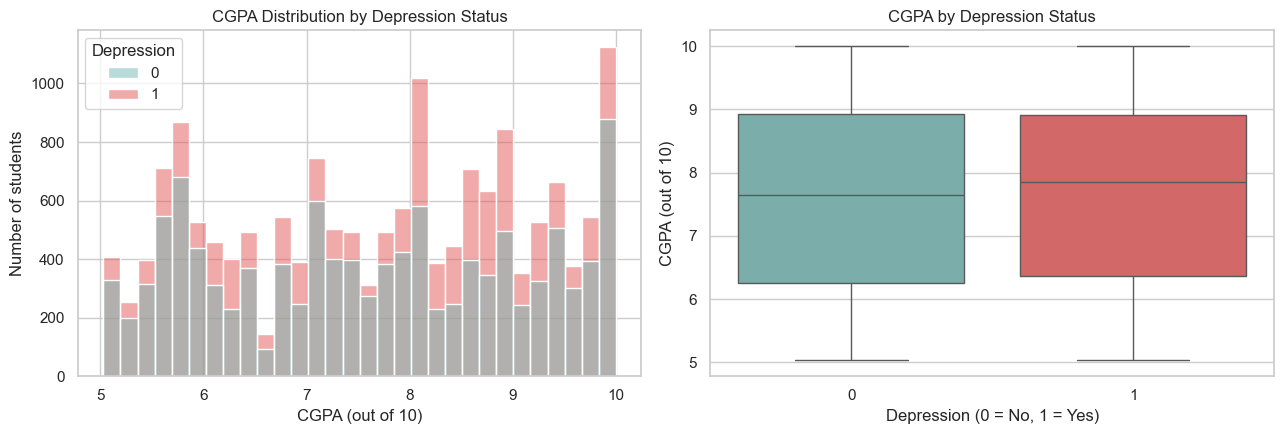

              count  mean   std   min   25%   50%   75%   max
Depression                                                   
0           11560.0  7.62  1.48  5.03  6.25  7.64  8.93  10.0
1           16332.0  7.69  1.45  5.03  6.37  7.85  8.91  10.0


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.histplot(data=df_clean, x="CGPA", hue="Depression", bins=30, multiple="layer", alpha=0.5,
             palette=[colour_not_depressed, colour_depressed], ax=axes[0])
axes[0].set_title("CGPA Distribution by Depression Status")
axes[0].set_xlabel("CGPA (out of 10)")
axes[0].set_ylabel("Number of students")

sns.boxplot(data=df_clean, x="Depression", y="CGPA", hue="Depression",
            palette=[colour_not_depressed, colour_depressed], legend=False, ax=axes[1])
axes[1].set_title("CGPA by Depression Status")
axes[1].set_xlabel("Depression (0 = No, 1 = Yes)")
axes[1].set_ylabel("CGPA (out of 10)")

plt.tight_layout()
plt.show()

print(df_clean.groupby("Depression")["CGPA"].describe().round(2))

### Observation

The two CGPA distributions overlap almost completely, and the average CGPA is almost identical for the two groups (about 7.62 vs 7.68). So **CGPA by itself is not a useful signal for depression in this dataset**, even though academic pressure is. A student's marks and the pressure they feel are clearly not the same thing.

### 5.6 Sleep Duration distribution and depression

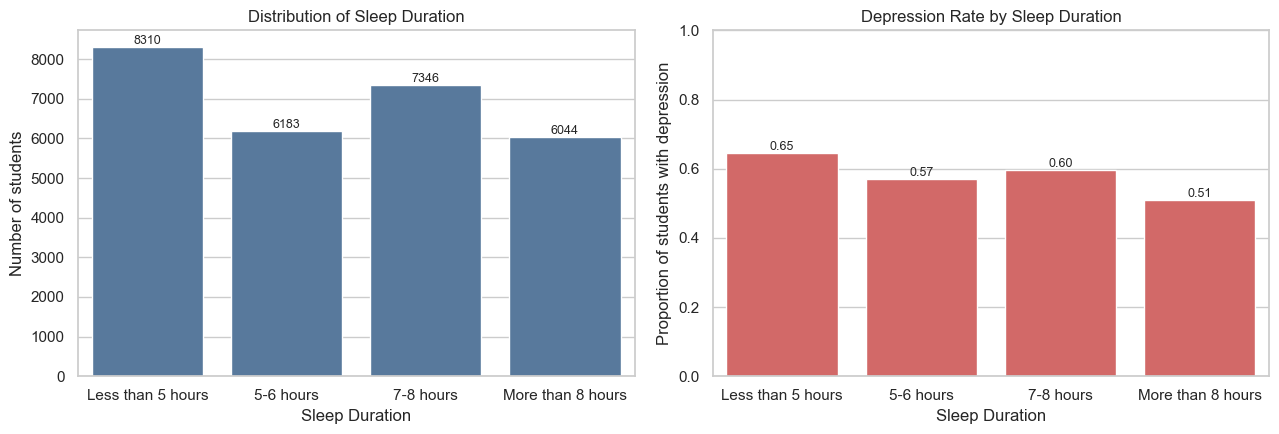

In [27]:
plot_distribution_and_depression_rate("Sleep Duration", order=sleep_order)

### Observation

The sleep categories have similar sizes (about 6,000–8,300 students each). Students sleeping **less than 5 hours** have the highest depression rate (about 64.5%) and students sleeping **more than 8 hours** have the lowest (about 50.9%). The pattern is not perfectly smooth, because the 5–6 hour group (about 56.9%) is lower than the 7–8 hour group (about 59.5%). So sleep is related to depression, but the effect is much weaker than that of academic pressure or financial stress.

### 5.7 Dietary Habits distribution and depression

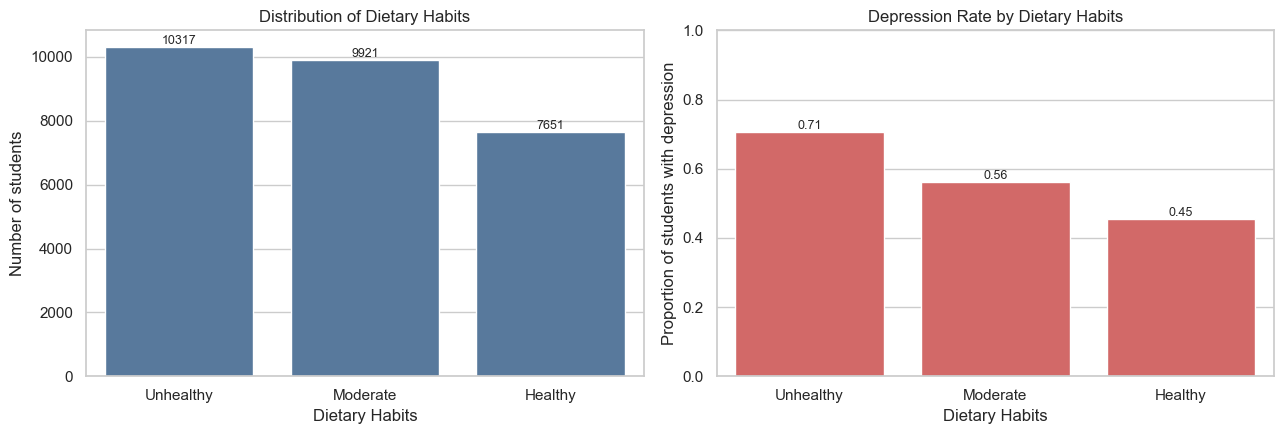

In [28]:
plot_distribution_and_depression_rate("Dietary Habits", order=diet_order)

### Observation

Most students report `Unhealthy` or `Moderate` diets. The depression rate decreases steadily as eating habits improve: about **70.7%** for unhealthy, **56.0%** for moderate and **45.4%** for healthy diets. Dietary habits show a clear, ordered relationship with the target, which justifies encoding them as an ordinal feature.

### 5.8 Financial Stress distribution and depression

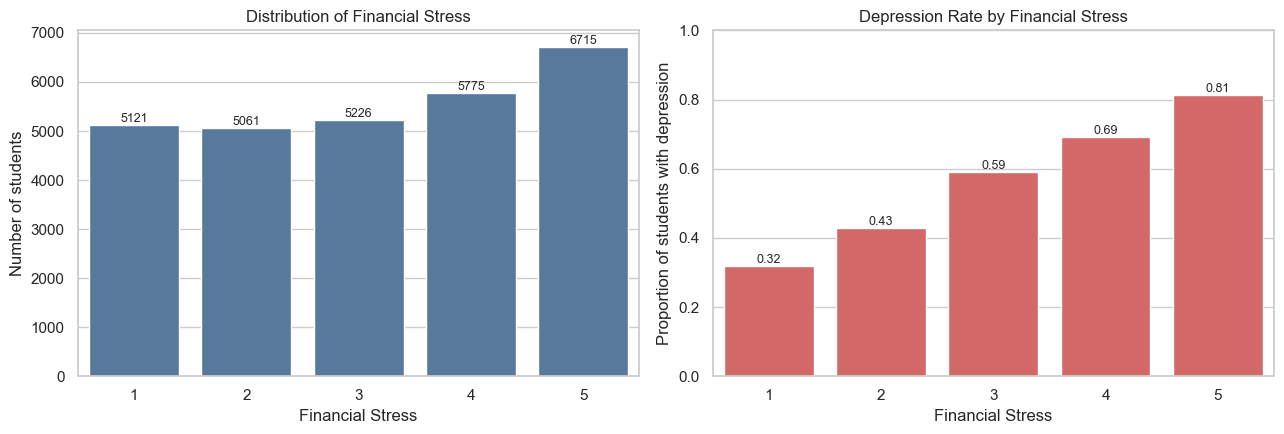

In [29]:
plot_distribution_and_depression_rate("Financial Stress", order=[1.0, 2.0, 3.0, 4.0, 5.0])

### Observation

All five stress levels have similar numbers of students (level 5 is the largest group). The depression rate increases consistently from about **32%** at level 1 to about **81%** at level 5. Financial stress is therefore another strong factor associated with depression.

### 5.9 Study Satisfaction distribution and depression

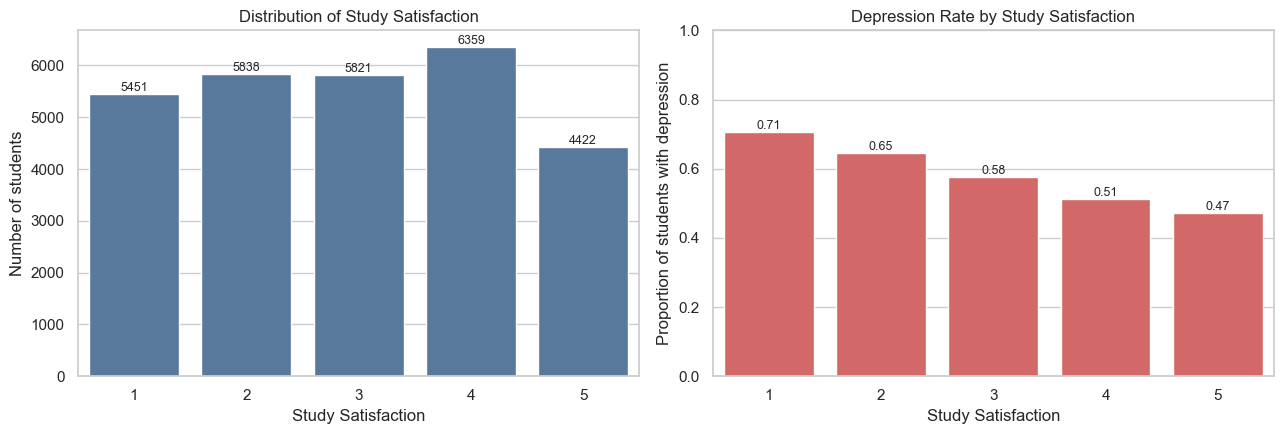

In [30]:
plot_distribution_and_depression_rate("Study Satisfaction", order=[1.0, 2.0, 3.0, 4.0, 5.0])

### Observation

The relationship is in the opposite direction compared with pressure and stress: the depression rate **decreases** as study satisfaction increases, from about 71% at level 1 to about 47% at level 5. The effect is real but smaller than that of academic pressure or financial stress.

### 5.10 Family History of Mental Illness and depression

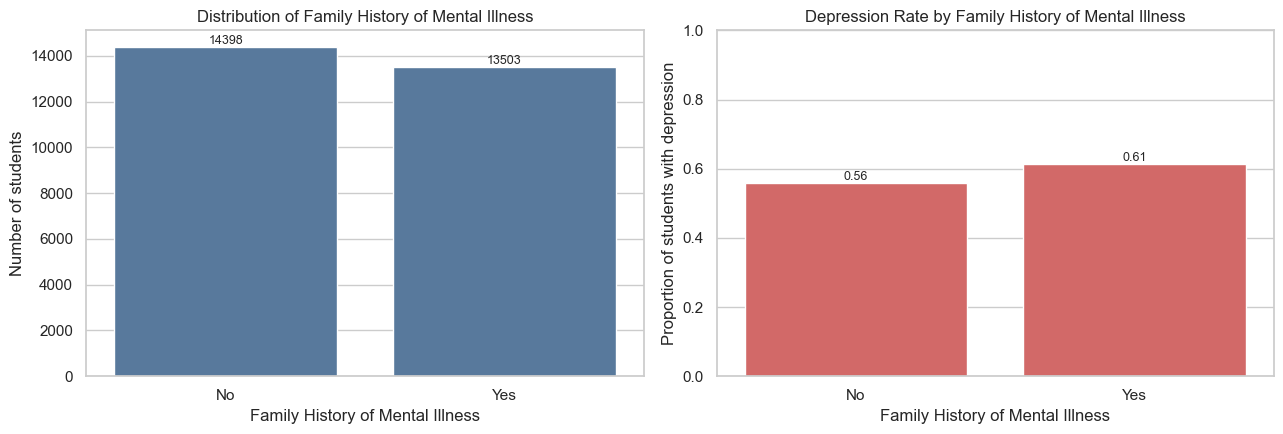

In [31]:
plot_distribution_and_depression_rate("Family History of Mental Illness")

### Observation

Students with a family history of mental illness are almost as common as students without one (about 48% vs 52%). The depression rate is slightly higher with a family history (about 61.3% vs 56.0%), a gap of about 5 percentage points. This is a small difference compared with the other factors above.

### 5.11 Suicidal Thoughts and depression

This feature is ethically sensitive (we discuss this in Section 6), but we must look at how strongly it is related to the target before deciding anything.

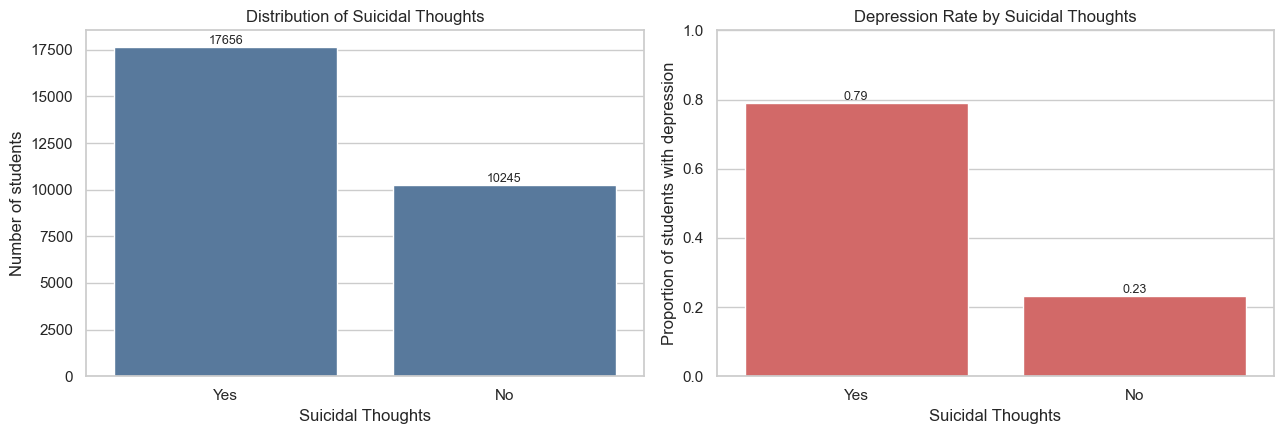

In [32]:
plot_distribution_and_depression_rate("Suicidal Thoughts")

### Observation

Students who answered `Yes` have a depression rate of about **79%**, compared with about **23%** for students who answered `No`. This is the largest difference of any feature in the dataset. It is also the feature that makes the prediction least useful as an early-warning tool, because a student who already reports suicidal thoughts is already known to be at serious risk.

### 5.12 Work/Study Hours and depression

Work/Study Hours is a whole number from 0 to 12, so a bar plot of the depression rate for each value is easy to read.

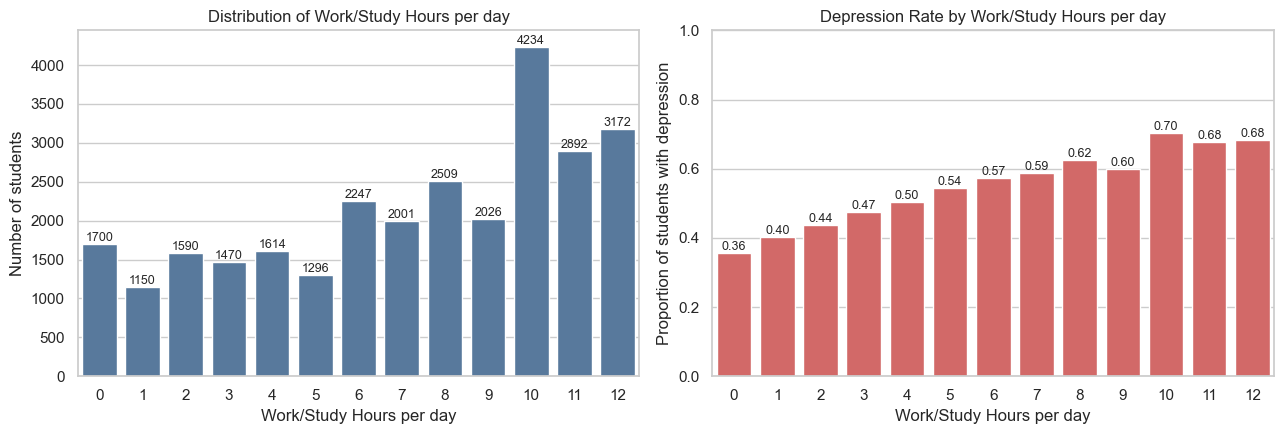

In [33]:
plot_distribution_and_depression_rate("Work/Study Hours", x_label="Work/Study Hours per day")

### Observation

The depression rate generally increases with more work/study hours: about 35% for 0 hours, about 59–62% around 7–9 hours, and about 68–70% for 10–12 hours. The largest group of students reports 10 hours. This is a moderate positive association.

### 5.13 Correlation heatmap of the numerical features

A correlation heatmap shows the linear relationship between the numerical columns and the target. Values near `+1` or `-1` mean a strong linear relationship; values near `0` mean almost none.

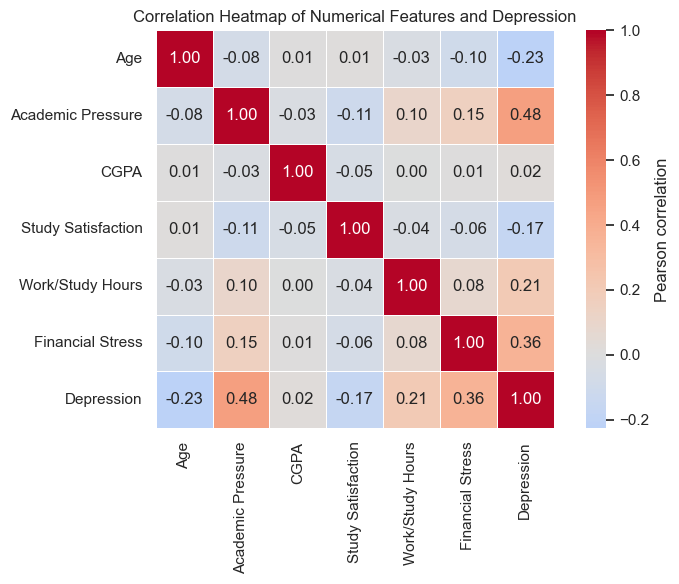

In [34]:
heatmap_columns = ["Age", "Academic Pressure", "CGPA", "Study Satisfaction",
                   "Work/Study Hours", "Financial Stress", "Depression"]
correlation_matrix = df_clean[heatmap_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Numerical Features and Depression")
plt.tight_layout()
plt.show()

### Observation

Correlation of each feature with `Depression`: **Academic Pressure +0.48** (strongest), **Financial Stress +0.36**, **Work/Study Hours +0.21**, **Age -0.23**, **Study Satisfaction -0.17** and **CGPA +0.02** (almost zero). The features are only weakly correlated with each other (the largest value is about 0.15, between Academic Pressure and Financial Stress), so each one adds mostly separate information, and multicollinearity is not a serious concern. This heatmap only shows *linear* relationships between numerical columns; binary and categorical features (such as Suicidal Thoughts) are not included.

### 5.14 Comparison between two important features

Academic Pressure and Financial Stress were the two strongest rating features above. We now check how they act **together** by drawing the depression rate for every combination of the two.

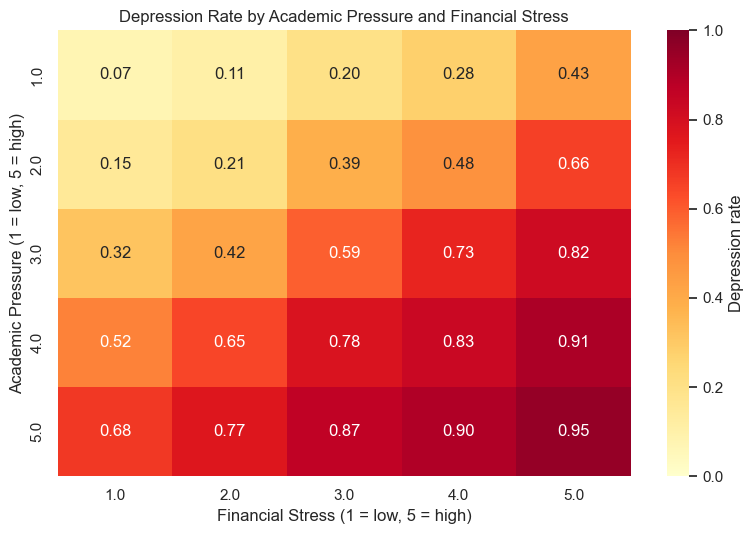

In [35]:
pressure_stress_table = df_clean.pivot_table(index="Academic Pressure", columns="Financial Stress",
                                             values="Depression", aggfunc="mean")

plt.figure(figsize=(8, 5.5))
sns.heatmap(pressure_stress_table, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1,
            cbar_kws={"label": "Depression rate"})
plt.title("Depression Rate by Academic Pressure and Financial Stress")
plt.xlabel("Financial Stress (1 = low, 5 = high)")
plt.ylabel("Academic Pressure (1 = low, 5 = high)")
plt.tight_layout()
plt.show()

### Observation

The depression rate rises when either factor increases, and the two effects add up. It is lowest (**0.07**) for students with Academic Pressure 1 and Financial Stress 1, and highest (**0.95**) for Academic Pressure 5 and Financial Stress 5. Moving along the first column (stress 1), the rate climbs from 0.07 to 0.68 as pressure increases; moving along the first row (pressure 1), it climbs from 0.07 to 0.43 as stress increases. So academic pressure seems to have the bigger effect, but high stress adds to it at every level. Every cell contains at least about 720 students, so these rates are based on reasonably large groups.

### 5.15 Summary of the EDA

- **Strong associations with depression:** Suicidal Thoughts, Academic Pressure, Financial Stress.
- **Moderate associations:** Dietary Habits, Age (younger students have a higher rate), Work/Study Hours, Study Satisfaction.
- **Weak associations:** Sleep Duration, Family History of Mental Illness.
- **Almost no association:** Gender, CGPA.

These are patterns in the data and not proof of cause and effect.

# Section 6: Feature Selection and Train-Test Split

### 6.1 Which features are useful for prediction?

Based on the cleaning and EDA, we keep the 13 features in `X`:

- **Useful (strong or moderate signal):** Suicidal Thoughts, Academic Pressure, Financial Stress, Dietary Habits, Age, Work/Study Hours, Study Satisfaction.
- **Weak signal (kept):** Sleep Duration, Family History of Mental Illness, Degree, City. We keep them because a model may find interactions that simple plots cannot show, and because removing features only because of a quick plot would be an unjustified decision.
- **Almost no signal (kept):** Gender and CGPA. We keep them too and let the feature-importance analysis in Section 10 show whether they matter.
- **Removed earlier:** `id`, `Profession`, `Work Pressure`, `Job Satisfaction` (Section 4.6).

### 6.2 The sensitive feature: "Have you ever had suicidal thoughts?"

This feature needs special discussion.

1. **Ethical concern.** It is a very sensitive piece of personal information. Collecting it, storing it and using it inside an automated prediction system raises privacy, consent and misuse concerns. Predictions based on such information could also label or stigmatise students.
2. **Usefulness as an early-warning system.** An *early-warning* tool should detect students at risk **before** they are already in serious distress. A student who already reports suicidal thoughts is already known to be at high risk, so a model that relies on this answer mostly repeats what the student has already told us.
3. **Possible "shortcut" effect.** In EDA the answer alone is strongly linked to depression (about 79% vs 23%). A model may rely on it heavily, which can hide the contribution of other, more actionable factors (such as pressure, stress and lifestyle).

**Our approach:** we do **not** silently remove this feature. The main models (Section 7) use all 13 features, exactly as in the dataset. In Section 9 we run a **separate experiment** in which all seven models are retrained without this feature, and compare the results.

### 6.3 Defining X and y

In [36]:
# X and y were created in Section 4.6. Here we confirm them.
print("Features (X):", X.shape)
print("Target (y):", y.shape)
print()
print("Columns in X:")
print(X.columns.tolist())

Features (X): (27901, 13)
Target (y): (27901,)

Columns in X:
['Gender', 'Age', 'City', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Sleep Duration', 'Dietary Habits', 'Degree', 'Suicidal Thoughts', 'Work/Study Hours', 'Financial Stress', 'Family History of Mental Illness']


### 6.4 Why a stratified train-test split?

We split the data into **80% training** and **20% testing**.

- The **training set** is used to learn the preprocessing values and to train the models.
- The **test set** is kept untouched until the final evaluation, so it gives an honest estimate of performance on unseen students.
- **Stratification** (`stratify=y`) keeps the same share of depressed and non-depressed students in both sets. Without it, a random split could, by chance, give the test set a different class balance from the training set, which makes the comparison less reliable.
- `random_state=42` makes the split reproducible.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,          # 20% of the data is kept for testing
    stratify=y,              # keep the class proportion the same in both sets
    random_state=RANDOM_STATE
)

print("Training set size:", X_train.shape[0], "students")
print("Test set size    :", X_test.shape[0], "students")
print()
print("Share of depressed students in the full data  :", round(y.mean(), 4))
print("Share of depressed students in the training set:", round(y_train.mean(), 4))
print("Share of depressed students in the test set    :", round(y_test.mean(), 4))

Training set size: 22320 students
Test set size    : 5581 students

Share of depressed students in the full data  : 0.5855
Share of depressed students in the training set: 0.5855
Share of depressed students in the test set    : 0.5856


### Observation

The training set has 22,320 students and the test set has 5,581 students. The proportion of depressed students is nearly identical (about 58.5%) in the full data, the training set and the test set, which confirms that stratification worked. From now on the test set is used **only for final evaluation**.

### 6.5 Preparing the "without suicidal thoughts" version for the later experiment

For the experiment in Section 9 we need the same split without the sensitive column. We simply drop that column from the already-split tables, so **exactly the same students** are in the training and test sets in both experiments.

In [38]:
X_train_without_sensitive = X_train.drop(columns=["Suicidal Thoughts"])
X_test_without_sensitive = X_test.drop(columns=["Suicidal Thoughts"])
binary_columns_without_sensitive = [column for column in binary_columns if column != "Suicidal Thoughts"]

print("Columns with the sensitive feature   :", X_train.shape[1])
print("Columns without the sensitive feature:", X_train_without_sensitive.shape[1])

Columns with the sensitive feature   : 13
Columns without the sensitive feature: 12


# Section 7: Building Machine Learning Models

We train **seven** classification models. Each model gets its own section, and each section follows the same steps: explain the algorithm, create the model inside a `Pipeline` (preprocessing + model), train it on the training set, predict on the test set, calculate the metrics and show the confusion matrix.

### How the pieces work together

`Pipeline([preprocessing, model])` guarantees that, when we call `.fit(X_train, y_train)`, the imputers, encoders and scalers are fitted **only on the training data**. When we call `.predict(X_test)`, the already-fitted preprocessing is only applied (transformed) to the test data. This is how we prevent data leakage.

First we create the containers that store results and three small helper functions.

In [39]:
# Containers that store everything we need for the comparison in Sections 8 and 9
trained_pipelines = {}     # fitted pipeline of every model
model_settings = {}        # (untrained model, needs_scaling) so the same model can be rebuilt for experiments
test_predictions = {}      # predicted classes on the test set
test_scores = {}           # probability / decision score (needed for ROC and PR curves)
results = {}               # evaluation metrics on the test set

class_labels = ["No Depression", "Depression"]


def get_scores(fitted_pipeline, features):
    # Return a continuous score for the positive class (used for ROC-AUC and ROC/PR curves)
    if hasattr(fitted_pipeline, "predict_proba"):
        return fitted_pipeline.predict_proba(features)[:, 1]
    return fitted_pipeline.decision_function(features)


def calculate_metrics(y_true, y_predicted, y_score):
    # The five evaluation metrics required for this project
    return {
        "Accuracy": accuracy_score(y_true, y_predicted),
        "Precision": precision_score(y_true, y_predicted),
        "Recall": recall_score(y_true, y_predicted),
        "F1-Score": f1_score(y_true, y_predicted),
        "ROC-AUC": roc_auc_score(y_true, y_score),
    }


def show_confusion_matrix(y_true, y_predicted, model_name):
    fig, ax = plt.subplots(figsize=(5, 4.2))
    ConfusionMatrixDisplay.from_predictions(y_true, y_predicted, display_labels=class_labels,
                                            cmap="Blues", values_format="d", ax=ax)
    ax.set_title(f"Confusion Matrix: {model_name}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.grid(False)
    plt.tight_layout()
    plt.show()


print("Containers and helper functions are ready.")

Containers and helper functions are ready.


### Observation

`get_scores` uses `predict_proba` when a model offers it and `decision_function` otherwise (our SVM). ROC-AUC and the ROC/PR curves only need a score that ranks students from "less likely" to "more likely" depressed, so both work.

## 7.1 Logistic Regression

**How the algorithm works (simple English):** Logistic Regression gives every feature a weight (coefficient), adds the weighted values together and converts the total into a probability between 0 and 1 using the S-shaped sigmoid function. If the probability is above 0.5, the student is predicted as depressed.

**Why we use it:** It is simple, fast and easy to interpret: the coefficients tell us the direction and strength of each feature. It is a good baseline model. It works best with scaled features, so we use `scale=True`.

Accuracy     0.8452
Precision    0.8594
Recall       0.8794
F1-Score     0.8693
ROC-AUC      0.9186
dtype: float64


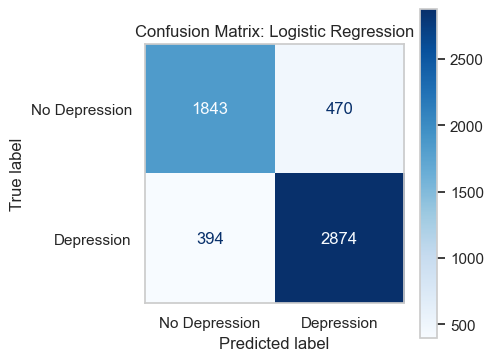

In [40]:
# Logistic Regression: features are scaled because the model uses weighted sums
log_reg_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(binary_columns, scale=True)),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

log_reg_pipeline.fit(X_train, y_train)                       # train (preprocessing is fitted on training data only)
y_pred_log_reg = log_reg_pipeline.predict(X_test)            # predict classes for the test set
y_score_log_reg = get_scores(log_reg_pipeline, X_test)       # probabilities for ROC-AUC

# Store everything for later comparison
model_name = "Logistic Regression"
trained_pipelines[model_name] = log_reg_pipeline
model_settings[model_name] = (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), True)
test_predictions[model_name] = y_pred_log_reg
test_scores[model_name] = y_score_log_reg
results[model_name] = calculate_metrics(y_test, y_pred_log_reg, y_score_log_reg)

print(pd.Series(results[model_name]).round(4))
show_confusion_matrix(y_test, y_pred_log_reg, model_name)

### Observation: Logistic Regression

Logistic Regression reaches an accuracy of **0.845**, precision **0.859**, recall **0.879**, F1 **0.869** and ROC-AUC **0.919**. In the confusion matrix it correctly finds 2,874 of the 3,268 depressed students (394 are missed: false negatives) and correctly identifies 1,843 of the 2,313 non-depressed students (470 are wrongly flagged: false positives). This simple, interpretable model is among the best performers, which suggests that the main relationships in this dataset are close to linear (rates rose steadily with pressure and stress in the EDA).

## 7.2 K-Nearest Neighbors (KNN)

**How the algorithm works (simple English):** KNN stores the training students. For a new student it finds the `k` most similar training students (the nearest neighbours, measured by distance) and predicts the class that most of them have. We use the default `k = 5`.

**Why we use it:** It is an easy-to-understand, non-parametric model that makes no assumption about the shape of the relationship. Because it relies on distances, features must be on the same scale, so we use `scale=True`.

Accuracy     0.8076
Precision    0.8140
Recall       0.8703
F1-Score     0.8412
ROC-AUC      0.8671
dtype: float64


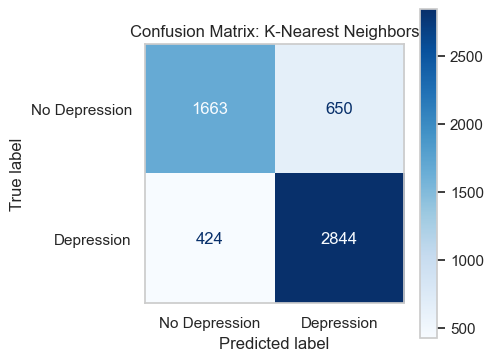

In [41]:
# KNN: distance-based, so scaling is required
knn_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(binary_columns, scale=True)),
    ("model", KNeighborsClassifier(n_neighbors=5)),
])

knn_pipeline.fit(X_train, y_train)
y_pred_knn = knn_pipeline.predict(X_test)
y_score_knn = get_scores(knn_pipeline, X_test)

model_name = "K-Nearest Neighbors"
trained_pipelines[model_name] = knn_pipeline
model_settings[model_name] = (KNeighborsClassifier(n_neighbors=5), True)
test_predictions[model_name] = y_pred_knn
test_scores[model_name] = y_score_knn
results[model_name] = calculate_metrics(y_test, y_pred_knn, y_score_knn)

print(pd.Series(results[model_name]).round(4))
show_confusion_matrix(y_test, y_pred_knn, model_name)

### Observation: K-Nearest Neighbors

KNN gets accuracy **0.808**, precision **0.814**, recall **0.870**, F1 **0.841** and ROC-AUC **0.867**. Its recall is good (it finds 2,844 of 3,268 depressed students), but it produces many false alarms: 650 non-depressed students are flagged (a false-positive rate of about 28%). A likely reason is that, after one-hot encoding, many of the 70 columns are sparse city and degree indicators. They add noise to the distance calculation, so the neighbours are less meaningful. Section 9.5 checks whether a larger `k` helps.

## 7.3 Decision Tree Classifier

**How the algorithm works (simple English):** A Decision Tree asks a series of yes/no questions about the features (for example, "Is Academic Pressure above 3?"). Each question splits the students into groups, and the final group (leaf) gives the prediction. We use the default settings, which let the tree grow until its leaves are pure.

**Why we use it:** It is easy to visualise and explain, needs no feature scaling and can capture non-linear patterns. A fully grown tree tends to overfit, which is a good lesson for comparison with the ensemble models. We use `scale=False`.

Training accuracy: 1.0
Accuracy     0.7710
Precision    0.8082
Recall       0.7983
F1-Score     0.8033
ROC-AUC      0.7654
dtype: float64


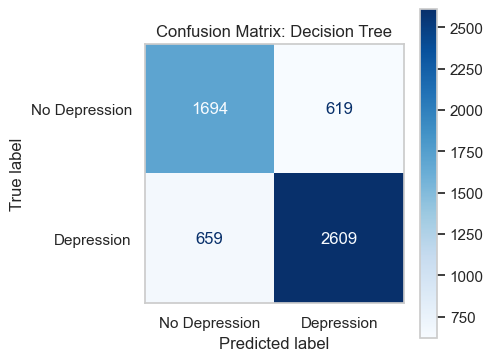

In [42]:
# Decision Tree: does not need scaling
decision_tree_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(binary_columns, scale=False)),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

decision_tree_pipeline.fit(X_train, y_train)
y_pred_tree = decision_tree_pipeline.predict(X_test)
y_score_tree = get_scores(decision_tree_pipeline, X_test)

model_name = "Decision Tree"
trained_pipelines[model_name] = decision_tree_pipeline
model_settings[model_name] = (DecisionTreeClassifier(random_state=RANDOM_STATE), False)
test_predictions[model_name] = y_pred_tree
test_scores[model_name] = y_score_tree
results[model_name] = calculate_metrics(y_test, y_pred_tree, y_score_tree)

# Training accuracy is shown to check for overfitting
print("Training accuracy:", round(decision_tree_pipeline.score(X_train, y_train), 4))
print(pd.Series(results[model_name]).round(4))
show_confusion_matrix(y_test, y_pred_tree, model_name)

### Observation: Decision Tree

The Decision Tree has a training accuracy of **1.000** but a test accuracy of only **0.771** (precision 0.808, recall 0.798, F1 0.803, ROC-AUC 0.765). This large gap is a clear sign of **overfitting**: the fully grown tree has memorised the training students. It misses 659 depressed students and flags 619 non-depressed ones. The ROC-AUC is low because a tree gives only a few distinct scores. A shallower tree should do better (checked in Section 9.5).

## 7.4 Random Forest Classifier

**How the algorithm works (simple English):** A Random Forest builds many decision trees, each on a random sample of the students and a random subset of features, and lets all trees vote. Averaging many different trees reduces the overfitting of a single tree.

**Why we use it:** It is usually much more stable and accurate than one tree, handles non-linear patterns, needs no scaling and gives feature importances. We use 100 trees (the default).

Training accuracy: 1.0
Accuracy     0.8355
Precision    0.8464
Recall       0.8785
F1-Score     0.8622
ROC-AUC      0.9144
dtype: float64


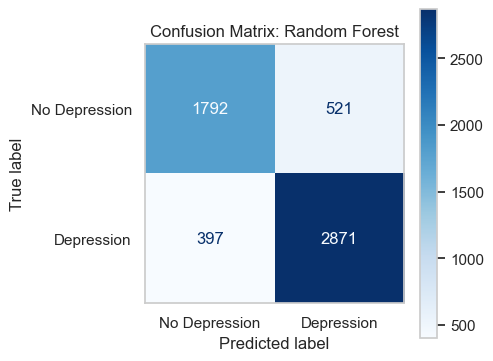

In [43]:
# Random Forest: 100 trees, does not need scaling
random_forest_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(binary_columns, scale=False)),
    ("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)),
])

random_forest_pipeline.fit(X_train, y_train)
y_pred_forest = random_forest_pipeline.predict(X_test)
y_score_forest = get_scores(random_forest_pipeline, X_test)

model_name = "Random Forest"
trained_pipelines[model_name] = random_forest_pipeline
model_settings[model_name] = (RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE), False)
test_predictions[model_name] = y_pred_forest
test_scores[model_name] = y_score_forest
results[model_name] = calculate_metrics(y_test, y_pred_forest, y_score_forest)

print("Training accuracy:", round(random_forest_pipeline.score(X_train, y_train), 4))
print(pd.Series(results[model_name]).round(4))
show_confusion_matrix(y_test, y_pred_forest, model_name)

### Observation: Random Forest

Random Forest has accuracy **0.836**, precision **0.846**, recall **0.879**, F1 **0.862** and ROC-AUC **0.914**, far better than the single tree. Its training accuracy is still 1.000, so each tree still fits the training data very closely, but averaging 100 trees makes the test performance much more stable. It is slightly behind Logistic Regression and Gradient Boosting here (397 missed depressed students and 521 false alarms).

## 7.5 Support Vector Machine (SVM)

**How the algorithm works (simple English):** An SVM looks for the boundary (a hyperplane) that separates the two classes with the largest possible margin. With the RBF kernel it can also draw curved boundaries by mapping the data into a higher-dimensional space.

**Why we use it:** It often performs well on medium-sized tabular data with many encoded features. It needs scaled features, so we use `scale=True`. We leave `probability=False` (the default) because computing probabilities is slow; ROC-AUC and the curves use the SVM's decision scores instead. This model takes the longest to train in this notebook (a few seconds to a minute).

Accuracy     0.8421
Precision    0.8481
Recall       0.8898
F1-Score     0.8684
ROC-AUC      0.9139
dtype: float64


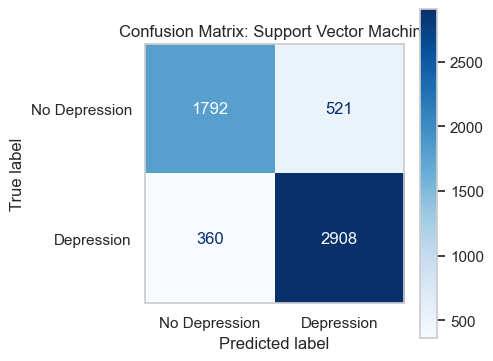

In [44]:
# SVM with RBF kernel: needs scaling. Training can take up to about a minute.
svm_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(binary_columns, scale=True)),
    ("model", SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE)),
])

svm_pipeline.fit(X_train, y_train)
y_pred_svm = svm_pipeline.predict(X_test)
y_score_svm = get_scores(svm_pipeline, X_test)       # decision_function scores

model_name = "Support Vector Machine"
trained_pipelines[model_name] = svm_pipeline
model_settings[model_name] = (SVC(kernel="rbf", C=1.0, gamma="scale", random_state=RANDOM_STATE), True)
test_predictions[model_name] = y_pred_svm
test_scores[model_name] = y_score_svm
results[model_name] = calculate_metrics(y_test, y_pred_svm, y_score_svm)

print(pd.Series(results[model_name]).round(4))
show_confusion_matrix(y_test, y_pred_svm, model_name)

### Observation: Support Vector Machine

The SVM gets accuracy **0.842**, precision **0.848**, recall **0.890**, F1 **0.868** and ROC-AUC **0.914**. It has the **highest recall** of all models: only 360 depressed students are missed (the fewest of all models), at the cost of 521 false alarms. Its F1 and ROC-AUC are close to those of Logistic Regression and Gradient Boosting, but it was the slowest model to train and it does not offer easy feature importances.

## 7.6 Naive Bayes (GaussianNB)

**How the algorithm works (simple English):** Naive Bayes uses Bayes' theorem. It calculates, for each class, how likely the observed feature values are and assumes that all features are independent of each other given the class. `GaussianNB` additionally assumes that every feature follows a bell-shaped (normal) distribution inside each class.

**Why we use it:** It is very fast and a classic baseline. **Is it appropriate here?** Only partly: after preprocessing, most of our features are 0/1 dummy columns (one-hot encoded cities and degrees, binary answers), and 0/1 columns are not bell-shaped. The independence assumption is also not realistic (for example, academic pressure and study hours are related). We still train `GaussianNB` as requested, but we expect it to be weaker than the other models and we explain this in the observation. (`BernoulliNB` or `CategoricalNB` would match the data representation better, but we keep `GaussianNB` as specified.) Scaling is not needed because the model fits a separate mean and variance for every feature.

Accuracy     0.7371
Precision    0.7876
Recall       0.7546
F1-Score     0.7707
ROC-AUC      0.8103
dtype: float64


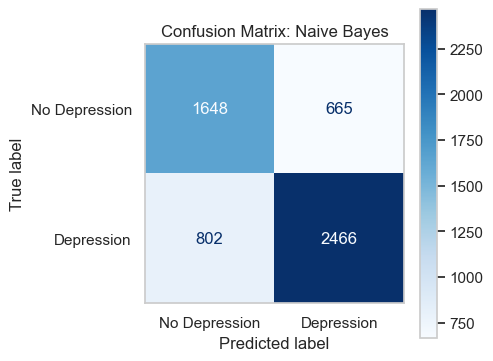

In [45]:
# GaussianNB: needs dense input (our encoder already returns dense arrays) and no scaling
naive_bayes_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(binary_columns, scale=False)),
    ("model", GaussianNB()),
])

naive_bayes_pipeline.fit(X_train, y_train)
y_pred_nb = naive_bayes_pipeline.predict(X_test)
y_score_nb = get_scores(naive_bayes_pipeline, X_test)

model_name = "Naive Bayes"
trained_pipelines[model_name] = naive_bayes_pipeline
model_settings[model_name] = (GaussianNB(), False)
test_predictions[model_name] = y_pred_nb
test_scores[model_name] = y_score_nb
results[model_name] = calculate_metrics(y_test, y_pred_nb, y_score_nb)

print(pd.Series(results[model_name]).round(4))
show_confusion_matrix(y_test, y_pred_nb, model_name)

### Observation: Gaussian Naive Bayes

Gaussian Naive Bayes is clearly the weakest model: accuracy **0.737**, precision **0.788**, recall **0.755**, F1 **0.771**, ROC-AUC **0.810**. It misses 802 depressed students (about 25% of them) and flags 665 non-depressed ones. This agrees with our expectation: most processed features are 0/1 columns that do not follow a normal distribution, and the features are not independent of each other (for example, pressure, stress and satisfaction are related).

## 7.7 Gradient Boosting Classifier

**How the algorithm works (simple English):** Gradient Boosting builds many small decision trees one after another. Each new tree tries to correct the mistakes made by the trees before it. The final prediction is the combined result of all trees.

**Why we use it:** Boosting is one of the strongest methods for tabular data. It needs no scaling and gives feature importances. We use the default settings: 100 trees, learning rate 0.1 and maximum depth 3.

Accuracy     0.8455
Precision    0.8566
Recall       0.8843
F1-Score     0.8702
ROC-AUC      0.9195
dtype: float64


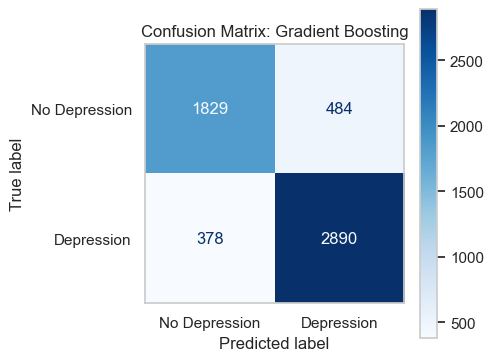

In [46]:
# Gradient Boosting: 100 shallow trees built one after another
gradient_boosting_pipeline = Pipeline([
    ("preprocessing", make_preprocessor(binary_columns, scale=False)),
    ("model", GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                         random_state=RANDOM_STATE)),
])

gradient_boosting_pipeline.fit(X_train, y_train)
y_pred_gb = gradient_boosting_pipeline.predict(X_test)
y_score_gb = get_scores(gradient_boosting_pipeline, X_test)

model_name = "Gradient Boosting"
trained_pipelines[model_name] = gradient_boosting_pipeline
model_settings[model_name] = (GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                                                         random_state=RANDOM_STATE), False)
test_predictions[model_name] = y_pred_gb
test_scores[model_name] = y_score_gb
results[model_name] = calculate_metrics(y_test, y_pred_gb, y_score_gb)

print(pd.Series(results[model_name]).round(4))
show_confusion_matrix(y_test, y_pred_gb, model_name)

### Observation: Gradient Boosting

Gradient Boosting reaches accuracy **0.846**, precision **0.857**, recall **0.884**, F1 **0.870** and ROC-AUC **0.920**, the best F1 and ROC-AUC among the seven models. It misses 378 depressed students and flags 484 non-depressed ones. Note that its lead over Logistic Regression is very small (see Section 9.2).

## 7.8 Check: all seven models trained successfully

Before moving to the evaluation, we confirm that all seven models have been trained and have stored results.

In [47]:
print("Number of trained models:", len(trained_pipelines))
for model_name in trained_pipelines:
    print(" -", model_name)
assert len(trained_pipelines) == 7, "Not all seven models were trained."

Number of trained models: 7
 - Logistic Regression
 - K-Nearest Neighbors
 - Decision Tree
 - Random Forest
 - Support Vector Machine
 - Naive Bayes
 - Gradient Boosting


# Section 8: Model Evaluation

### 8.1 What each metric means (simple English)

In our problem the **positive class** is "Depression = 1".

| Metric | Meaning | Simple question it answers |
|---|---|---|
| **Accuracy** | Share of all predictions that are correct. | "How often is the model right overall?" Can be misleading when classes are imbalanced. |
| **Precision** | Of the students predicted as depressed, the share that really are. | "When the model says *depressed*, how often is it right?" Low precision means many false alarms. |
| **Recall** (sensitivity) | Of the students who really are depressed, the share the model finds. | "How many of the depressed students does the model catch?" Low recall means many missed students. |
| **F1-Score** | Harmonic mean of precision and recall. | "Is the balance between false alarms and missed cases good?" |
| **ROC-AUC** | Ability of the model's scores to rank depressed students above non-depressed ones, across *all* thresholds. 0.5 = random guessing, 1.0 = perfect. | "How well does the model separate the two groups, regardless of the threshold?" |
| **Confusion matrix** | Table of True Negatives (TN), False Positives (FP), False Negatives (FN) and True Positives (TP). | "What exactly are the mistakes?" |

### 8.2 False positives and false negatives in a mental-health setting

- A **false negative (FN)** is a depressed student whom the model calls "not depressed". The student is **missed** and may get no support. In a screening setting this is usually the more serious error, so **Recall** is very important.
- A **false positive (FP)** is a non-depressed student whom the model calls "depressed". This causes unnecessary worry, extra follow-up work and possible stigma, but it is usually less harmful than missing a student who needs help.
- Neither error can be ignored, which is why we judge models using a combination of Precision, Recall, F1 and ROC-AUC, and not accuracy alone.

### 8.3 Classification reports

`classification_report` shows precision, recall and F1 for **both** classes separately, which tells us how the model behaves for non-depressed students as well as for depressed ones.

In [48]:
for model_name in trained_pipelines:
    print("=" * 60)
    print(model_name)
    print("=" * 60)
    print(classification_report(y_test, test_predictions[model_name], target_names=class_labels, digits=4))

Logistic Regression
               precision    recall  f1-score   support

No Depression     0.8239    0.7968    0.8101      2313
   Depression     0.8594    0.8794    0.8693      3268

     accuracy                         0.8452      5581
    macro avg     0.8417    0.8381    0.8397      5581
 weighted avg     0.8447    0.8452    0.8448      5581

K-Nearest Neighbors
               precision    recall  f1-score   support

No Depression     0.7968    0.7190    0.7559      2313
   Depression     0.8140    0.8703    0.8412      3268

     accuracy                         0.8076      5581
    macro avg     0.8054    0.7946    0.7985      5581
 weighted avg     0.8069    0.8076    0.8058      5581

Decision Tree
               precision    recall  f1-score   support

No Depression     0.7199    0.7324    0.7261      2313
   Depression     0.8082    0.7983    0.8033      3268

     accuracy                         0.7710      5581
    macro avg     0.7641    0.7654    0.7647      5581
 we

### Observation

For all models, the depressed class (the larger one) has higher recall than the non-depressed class. For example, Logistic Regression has a recall of 0.879 for depressed students and 0.797 for non-depressed students. The models therefore find depressed students more reliably than they correctly clear non-depressed students, which means false alarms are more common than in a balanced problem. The macro-average F1 (which treats both classes equally) is about 0.84 for the top four models, lower than their F1 for the depressed class alone (about 0.86–0.87), so looking only at the depressed class would slightly overstate overall quality.

### 8.4 Confusion matrix numbers: false positives and false negatives

We collect the confusion-matrix counts of all models in one table and add the **false-negative rate** (share of depressed students that were missed) and the **false-positive rate** (share of non-depressed students wrongly flagged).

In [49]:
error_rows = []
for model_name in trained_pipelines:
    true_negatives, false_positives, false_negatives, true_positives = confusion_matrix(
        y_test, test_predictions[model_name]).ravel()
    error_rows.append({
        "Model": model_name,
        "True Negatives": true_negatives,
        "False Positives": false_positives,
        "False Negatives": false_negatives,
        "True Positives": true_positives,
        "False Negative Rate": false_negatives / (false_negatives + true_positives),
        "False Positive Rate": false_positives / (false_positives + true_negatives),
    })

error_table = pd.DataFrame(error_rows).round(4)
error_table

,Model,True Negatives,False Positives,False Negatives,True Positives,False Negative Rate,False Positive Rate
0,Logistic Regression,1843,470,394,2874,0.1206,0.2032
1,K-Nearest Neighbors,1663,650,424,2844,0.1297,0.2810
2,Decision Tree,1694,619,659,2609,0.2017,0.2676
3,Random Forest,1792,521,397,2871,0.1215,0.2252
4,Support Vector Machine,1792,521,360,2908,0.1102,0.2252
5,Naive Bayes,1648,665,802,2466,0.2454,0.2875
6,Gradient Boosting,1829,484,378,2890,0.1157,0.2093


### Observation

The SVM has the lowest false-negative rate (**11.0%**, 360 missed students), followed by Gradient Boosting (11.6%), Logistic Regression (12.1%) and Random Forest (12.2%). Naive Bayes (24.5%) and the Decision Tree (20.2%) miss the most. For false positives, Logistic Regression (20.3%) and Gradient Boosting (20.9%) are best, while Naive Bayes (28.8%) and KNN (28.1%) raise the most false alarms. Even the best models miss about 1 in 9 depressed students and wrongly flag about 1 in 5 non-depressed students at the default threshold of 0.5. If this were a screening tool, a lower threshold could be chosen to miss fewer students, but it would increase false alarms.

### 8.5 ROC curves

The ROC curve plots the True Positive Rate (recall) against the False Positive Rate for every possible decision threshold. A curve closer to the top-left corner is better. The dashed diagonal is random guessing.

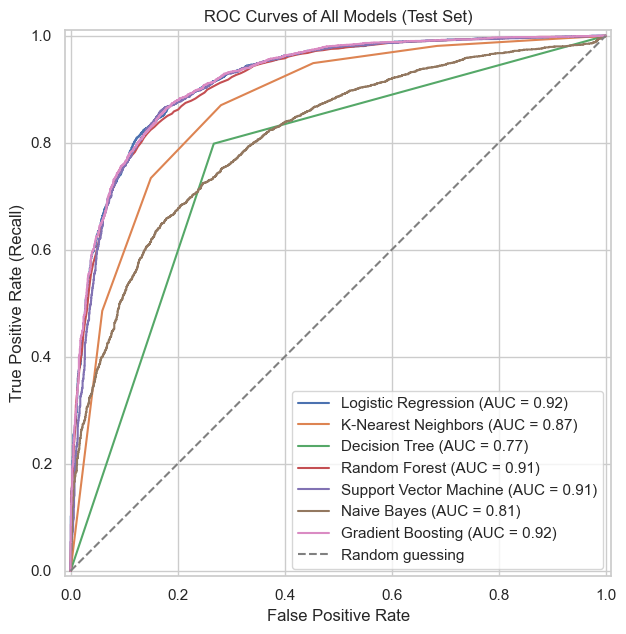

In [50]:
plt.figure(figsize=(8, 6.5))
for model_name in trained_pipelines:
    RocCurveDisplay.from_predictions(y_test, test_scores[model_name], name=model_name, ax=plt.gca())
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guessing")
plt.title("ROC Curves of All Models (Test Set)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Observation

Logistic Regression and Gradient Boosting (AUC about 0.92) have almost overlapping curves and lie closest to the top-left corner. Random Forest and SVM follow (AUC about 0.91). KNN (0.87), Naive Bayes (0.81) and the Decision Tree (0.77; its curve has only a few corner points because it gives few distinct scores) are clearly lower. All models are above the random-guessing diagonal, so every model learned some real signal.

### 8.6 Precision-Recall curves

The Precision-Recall curve shows the trade-off between precision and recall for different thresholds. It is useful here because the depressed class is the larger one and we care specifically about finding that class. The baseline is the share of depressed students (about 0.585).

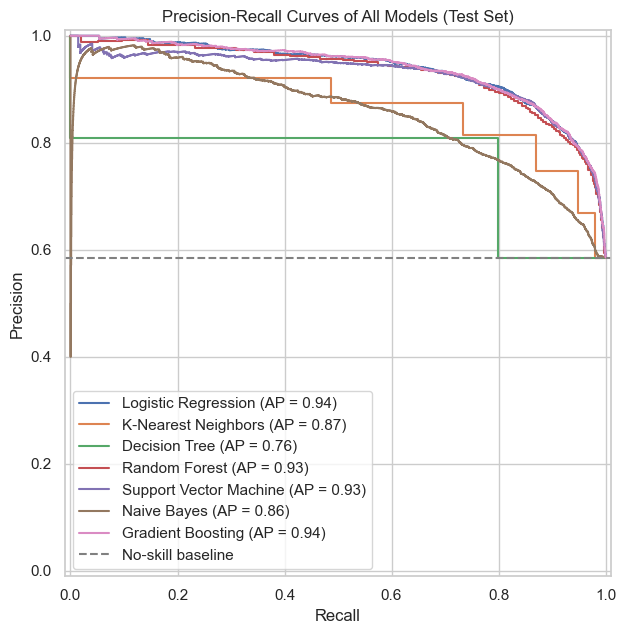

In [51]:
plt.figure(figsize=(8, 6.5))
for model_name in trained_pipelines:
    PrecisionRecallDisplay.from_predictions(y_test, test_scores[model_name], name=model_name, ax=plt.gca())
plt.axhline(y_test.mean(), linestyle="--", color="grey", label="No-skill baseline")
plt.title("Precision-Recall Curves of All Models (Test Set)")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Observation

The Precision-Recall curves tell the same story. Logistic Regression and Gradient Boosting (average precision about 0.94) and Random Forest and SVM (about 0.93) keep precision above roughly 0.9 until recall is about 0.75, then precision falls as more depressed students are captured. KNN (0.87), Naive Bayes (0.86) and the Decision Tree (0.76) are lower. All curves are above the no-skill baseline of about 0.585.

### 8.7 Cross-validation (checking stability of the results)

A single train-test split can be lucky or unlucky. To check how stable each model is, we run **5-fold stratified cross-validation on the training set only**. The pipeline is refitted inside each fold, so preprocessing never sees the validation fold of that round (no leakage). The test set is not touched. We record the mean and standard deviation of F1 and ROC-AUC. The SVM makes this step take a few minutes.

In [52]:
cross_validation_splitter = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cross_validation_rows = []

for model_name, (estimator, needs_scaling) in model_settings.items():
    cv_pipeline = Pipeline([
        ("preprocessing", make_preprocessor(binary_columns, scale=needs_scaling)),
        ("model", clone(estimator)),
    ])
    cv_result = cross_validate(cv_pipeline, X_train, y_train, cv=cross_validation_splitter,
                               scoring=["f1", "roc_auc"], n_jobs=2)
    cross_validation_rows.append({
        "Model": model_name,
        "CV F1 Mean": cv_result["test_f1"].mean(),
        "CV F1 Std": cv_result["test_f1"].std(),
        "CV ROC-AUC Mean": cv_result["test_roc_auc"].mean(),
        "CV ROC-AUC Std": cv_result["test_roc_auc"].std(),
    })

cross_validation_table = pd.DataFrame(cross_validation_rows).round(4)
cross_validation_table

,Model,CV F1 Mean,CV F1 Std,CV ROC-AUC Mean,CV ROC-AUC Std
0,Logistic Regression,0.8722,0.0012,0.9212,0.0024
1,K-Nearest Neighbors,0.8441,0.0039,0.8669,0.0047
2,Decision Tree,0.8099,0.0049,0.7704,0.0072
3,Random Forest,0.8680,0.0014,0.9136,0.0029
4,Support Vector Machine,0.8698,0.0024,0.9140,0.0020
5,Naive Bayes,0.7631,0.0072,0.7994,0.0100
6,Gradient Boosting,0.8713,0.0019,0.9206,0.0025


### Observation

Cross-validation on the training set gives the same picture as the test set. Mean F1: Logistic Regression 0.872, Gradient Boosting 0.871, SVM 0.870, Random Forest 0.868, KNN 0.844, Decision Tree 0.810, Naive Bayes 0.763. The standard deviations are small (about 0.001–0.007), so the results are stable. The top four models differ by only about 0.004 in F1, which is only a few standard deviations, so the differences among them should not be over-interpreted. In cross-validation, Logistic Regression is even slightly ahead of Gradient Boosting (F1 0.8722 vs 0.8713 and ROC-AUC 0.9212 vs 0.9206), whereas on the test set Gradient Boosting is marginally ahead. This shows the two models are effectively tied.

### 8.8 Model comparison table and bar chart

We now combine the test-set metrics of all models in one table and plot them side by side.

In [53]:
comparison_table = pd.DataFrame(results).T.round(4)
comparison_table.index.name = "Model"
comparison_table = comparison_table.reset_index()
comparison_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8452,0.8594,0.8794,0.8693,0.9186
1,K-Nearest Neighbors,0.8076,0.8140,0.8703,0.8412,0.8671
2,Decision Tree,0.7710,0.8082,0.7983,0.8033,0.7654
3,Random Forest,0.8355,0.8464,0.8785,0.8622,0.9144
4,Support Vector Machine,0.8421,0.8481,0.8898,0.8684,0.9139
5,Naive Bayes,0.7371,0.7876,0.7546,0.7707,0.8103
6,Gradient Boosting,0.8455,0.8566,0.8843,0.8702,0.9195


### Bar chart of all metrics

A grouped bar chart makes it easier to compare the five metrics of the seven models at a glance. The y-axis starts at 0.6 so that the differences between the models are visible.

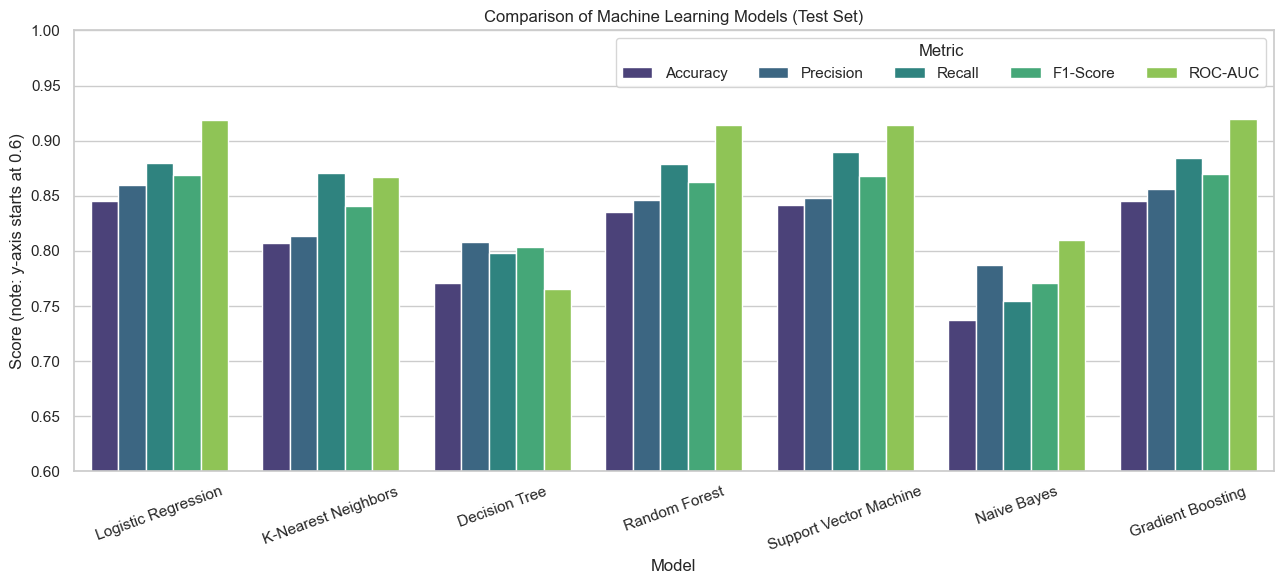

In [54]:
# Bar chart: all five metrics for all models
metrics_long = comparison_table.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(13, 6))
sns.barplot(data=metrics_long, x="Model", y="Score", hue="Metric", palette="viridis")
plt.title("Comparison of Machine Learning Models (Test Set)")
plt.xlabel("Model")
plt.ylabel("Score (note: y-axis starts at 0.6)")
plt.ylim(0.6, 1.0)
plt.xticks(rotation=20)
plt.legend(title="Metric", loc="upper right", ncol=5)
plt.tight_layout()
plt.show()

### Observation

Four models (Gradient Boosting, Logistic Regression, SVM, Random Forest) form a close top group with F1 between 0.862 and 0.870 and ROC-AUC between 0.914 and 0.920. KNN is clearly behind, and the Decision Tree and Naive Bayes are lowest. Remember that the y-axis starts at 0.6, so differences look larger in the chart than they really are. Recall (green-teal bars) is higher than precision for every model except the Decision Tree and Naive Bayes, which means these models lean towards predicting "depressed".

# Section 9: Model Comparison and Best Model Selection

### 9.1 Final comparison table

The table below is the final comparison of the seven models on the test set, sorted by F1-Score. The cross-validation results from Section 8.7 are added as extra columns so that we can see whether the ranking on the test set is also stable inside the training data.

In [55]:
final_comparison = comparison_table.merge(cross_validation_table, on="Model")
final_comparison = final_comparison.sort_values("F1-Score", ascending=False).reset_index(drop=True)
final_comparison

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV F1 Mean,CV F1 Std,CV ROC-AUC Mean,CV ROC-AUC Std
0,Gradient Boosting,0.8455,0.8566,0.8843,0.8702,0.9195,0.8713,0.0019,0.9206,0.0025
1,Logistic Regression,0.8452,0.8594,0.8794,0.8693,0.9186,0.8722,0.0012,0.9212,0.0024
2,Support Vector Machine,0.8421,0.8481,0.8898,0.8684,0.9139,0.8698,0.0024,0.9140,0.0020
3,Random Forest,0.8355,0.8464,0.8785,0.8622,0.9144,0.8680,0.0014,0.9136,0.0029
4,K-Nearest Neighbors,0.8076,0.8140,0.8703,0.8412,0.8671,0.8441,0.0039,0.8669,0.0047
5,Decision Tree,0.7710,0.8082,0.7983,0.8033,0.7654,0.8099,0.0049,0.7704,0.0072
6,Naive Bayes,0.7371,0.7876,0.7546,0.7707,0.8103,0.7631,0.0072,0.7994,0.0100


### 9.2 Selecting the best model

We do **not** choose by accuracy alone. We rank the models separately by **F1-Score** (balance of precision and recall) and **ROC-AUC** (ranking quality across all thresholds) and take the average rank. We then also look at Recall, because missing depressed students (false negatives) is costly, and at the cross-validation standard deviation to see whether differences are bigger than random variation.

In [56]:
ranking_table = final_comparison[["Model", "Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].copy()
ranking_table["Rank F1"] = ranking_table["F1-Score"].rank(ascending=False)
ranking_table["Rank ROC-AUC"] = ranking_table["ROC-AUC"].rank(ascending=False)
ranking_table["Rank Recall"] = ranking_table["Recall"].rank(ascending=False)
ranking_table["Average Rank (F1, ROC-AUC)"] = (ranking_table["Rank F1"] + ranking_table["Rank ROC-AUC"]) / 2
ranking_table = ranking_table.sort_values(["Average Rank (F1, ROC-AUC)", "Rank Recall"]).reset_index(drop=True)

best_model_name = ranking_table.loc[0, "Model"]
worst_model_name = ranking_table.loc[len(ranking_table) - 1, "Model"]

print("Best model (lowest average rank of F1 and ROC-AUC):", best_model_name)
print("Worst model:", worst_model_name)
ranking_table

Best model (lowest average rank of F1 and ROC-AUC): Gradient Boosting
Worst model: Naive Bayes


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Rank F1,Rank ROC-AUC,Rank Recall,"Average Rank (F1, ROC-AUC)"
0,Gradient Boosting,0.8455,0.8566,0.8843,0.8702,0.9195,1.0,1.0,2.0,1.0
1,Logistic Regression,0.8452,0.8594,0.8794,0.8693,0.9186,2.0,2.0,3.0,2.0
2,Support Vector Machine,0.8421,0.8481,0.8898,0.8684,0.9139,3.0,4.0,1.0,3.5
3,Random Forest,0.8355,0.8464,0.8785,0.8622,0.9144,4.0,3.0,4.0,3.5
4,K-Nearest Neighbors,0.8076,0.8140,0.8703,0.8412,0.8671,5.0,5.0,5.0,5.0
5,Decision Tree,0.7710,0.8082,0.7983,0.8033,0.7654,6.0,7.0,6.0,6.5
6,Naive Bayes,0.7371,0.7876,0.7546,0.7707,0.8103,7.0,6.0,7.0,6.5


### Observation

**Gradient Boosting** has the best average rank (rank 1 in both F1 = 0.870 and ROC-AUC = 0.920; accuracy 0.846, precision 0.857, recall 0.884). **Logistic Regression** is a very close second (F1 0.869, ROC-AUC 0.919): the difference is only about 0.001. The SVM has the highest recall (0.890) but a lower ROC-AUC. **Naive Bayes** is the worst overall: it has the lowest accuracy, precision, recall and F1. The Decision Tree has the lowest ROC-AUC and ties with Naive Bayes on the average rank (6.5), so Recall was used as the tie-breaker.

### 9.3 Discussion

**Which model performed best?** Gradient Boosting, but only by a hair. Its lead over Logistic Regression (and even over the SVM and Random Forest) is smaller than the variation seen in cross-validation, so the top four models are practically equal in performance.

**Which model performed worst?** Gaussian Naive Bayes (lowest accuracy, precision, recall and F1), with the Decision Tree close behind (lowest ROC-AUC).

**Why do the models differ?**
- The strongest signals in this data (Suicidal Thoughts, Academic Pressure, Financial Stress) act in a steady, nearly linear way, so a simple Logistic Regression can capture almost everything, and the more complex models add little.
- A single Decision Tree overfits (training accuracy 1.00 vs test 0.77), while Random Forest and Gradient Boosting reduce this by combining many trees.
- KNN is hurt by the many sparse one-hot columns (city, degree), which make distances less meaningful.
- Naive Bayes assumes independent, bell-shaped features, which is not true for our 0/1 and rating columns.

**Best balance between performance and interpretability:** **Logistic Regression**. It is within about 0.001 of the best F1 and ROC-AUC, it was even slightly better in cross-validation, it trains in a fraction of a second, and its coefficients are easy to explain (Section 10.2).

**Limitations of the selected model (Gradient Boosting):** it is harder to explain than Logistic Regression; its impurity-based importances can be misleading; it relies heavily on the sensitive `Suicidal Thoughts` feature (Section 9.4 and 10.3); at the default threshold it still misses about 11.6% of depressed students and flags about 21% of non-depressed students; and, because the origin of the dataset and its labels is unknown, we cannot say how well it would work on other student populations.

### 9.4 Separate experiment: models without the "Suicidal Thoughts" feature

As planned in Section 6.2, we now retrain **all seven models** with exactly the same settings, the same split and the same preprocessing, but **without** the `Suicidal Thoughts` column. This shows how much of the performance depends on this one sensitive feature, and how well the models perform as a more realistic *early-warning* tool.

In [57]:
experiment_results = {}

for model_name, (estimator, needs_scaling) in model_settings.items():
    experiment_pipeline = Pipeline([
        ("preprocessing", make_preprocessor(binary_columns_without_sensitive, scale=needs_scaling)),
        ("model", clone(estimator)),
    ])
    experiment_pipeline.fit(X_train_without_sensitive, y_train)
    experiment_predictions = experiment_pipeline.predict(X_test_without_sensitive)
    experiment_scores = get_scores(experiment_pipeline, X_test_without_sensitive)
    experiment_results[model_name] = calculate_metrics(y_test, experiment_predictions, experiment_scores)

experiment_table = pd.DataFrame(experiment_results).T.round(4)
experiment_table.index.name = "Model"
experiment_table = experiment_table.reset_index()
experiment_table

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7959,0.8121,0.8476,0.8295,0.8668
1,K-Nearest Neighbors,0.7622,0.7793,0.8286,0.8032,0.8131
2,Decision Tree,0.7115,0.7549,0.7512,0.7531,0.7033
3,Random Forest,0.7904,0.8083,0.8415,0.8246,0.8598
4,Support Vector Machine,0.7956,0.8062,0.8568,0.8307,0.8588
5,Naive Bayes,0.6721,0.7243,0.7105,0.7173,0.7275
6,Gradient Boosting,0.7968,0.8114,0.8507,0.8306,0.8691


### Comparing the two settings

We now calculate how much each metric changes when the sensitive feature is removed (a negative number means a drop) and draw F1-Score and ROC-AUC with and without the feature.

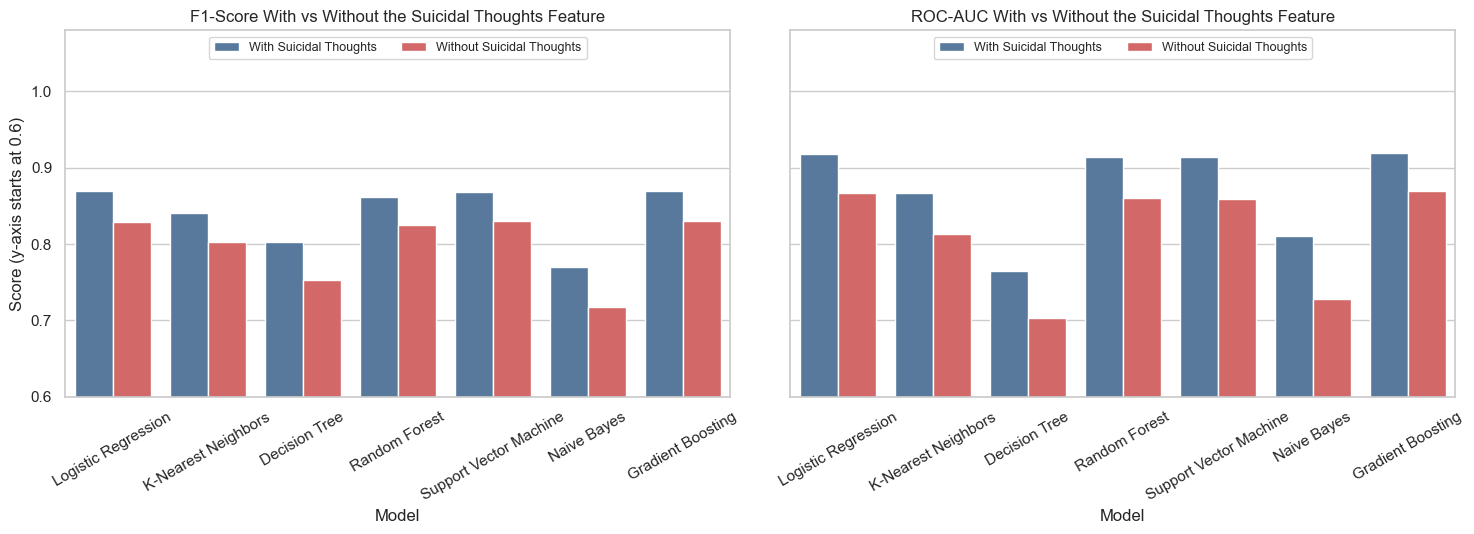

,Change in Accuracy,Change in Recall,Change in F1-Score,Change in ROC-AUC
Model,,,,
Logistic Regression,-0.0493,-0.0318,-0.0398,-0.0518
K-Nearest Neighbors,-0.0454,-0.0417,-0.0380,-0.0540
Decision Tree,-0.0595,-0.0471,-0.0502,-0.0621
Random Forest,-0.0451,-0.0370,-0.0376,-0.0546
Support Vector Machine,-0.0465,-0.0330,-0.0377,-0.0551
Naive Bayes,-0.0650,-0.0441,-0.0534,-0.0828
Gradient Boosting,-0.0487,-0.0336,-0.0396,-0.0504


In [58]:
# Side-by-side comparison: with vs without the sensitive feature
with_feature = comparison_table.set_index("Model")[["Accuracy", "Recall", "F1-Score", "ROC-AUC"]]
without_feature = experiment_table.set_index("Model")[["Accuracy", "Recall", "F1-Score", "ROC-AUC"]]

difference_table = (without_feature - with_feature).round(4)
difference_table.columns = [f"Change in {column}" for column in difference_table.columns]

# Bar chart of F1-Score and ROC-AUC with and without the feature
plot_rows = []
for model_name in with_feature.index:
    for metric in ["F1-Score", "ROC-AUC"]:
        plot_rows.append({"Model": model_name, "Metric": metric, "Setting": "With Suicidal Thoughts",
                          "Score": with_feature.loc[model_name, metric]})
        plot_rows.append({"Model": model_name, "Metric": metric, "Setting": "Without Suicidal Thoughts",
                          "Score": without_feature.loc[model_name, metric]})
plot_table = pd.DataFrame(plot_rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for axis, metric in zip(axes, ["F1-Score", "ROC-AUC"]):
    sns.barplot(data=plot_table[plot_table["Metric"] == metric], x="Model", y="Score", hue="Setting",
                palette=[colour_main, colour_depressed], ax=axis)
    axis.set_title(f"{metric} With vs Without the Suicidal Thoughts Feature")
    axis.set_xlabel("Model")
    axis.set_ylabel("Score (y-axis starts at 0.6)")
    axis.set_ylim(0.6, 1.08)
    axis.legend(loc="upper center", ncol=2, fontsize=9, title=None)
    axis.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

difference_table

### Observation

Removing `Suicidal Thoughts` lowers the performance of **every** model. The F1-Score drops by about 0.038–0.053 and the ROC-AUC by about 0.050–0.083. For the top models: Gradient Boosting F1 0.870 to 0.831 and ROC-AUC 0.920 to 0.869; Logistic Regression F1 0.869 to 0.830 and ROC-AUC 0.919 to 0.867. Naive Bayes and the Decision Tree are hit hardest (ROC-AUC 0.810 to 0.728 and 0.765 to 0.703). However, the best models still reach an ROC-AUC of about 0.86–0.87 and F1 of about 0.83 using only academic, lifestyle and demographic information, so these features carry real signal, and a model without the sensitive question can still rank students by risk reasonably well. The ranking of models stays almost the same (Gradient Boosting, Logistic Regression, SVM and Random Forest on top; Decision Tree and Naive Bayes at the bottom). This is the more realistic setting for an early-warning tool, but the model is still not a diagnostic system.

### 9.5 Optional: light hyperparameter tuning

So far, almost all models use their default settings. As an optional extra, we tune a few important hyperparameters with `GridSearchCV` (5-fold, scored by F1) on the **training set only**; the test set is used only once at the end to evaluate the tuned model. To keep the notebook fast, we tune the five models that train quickly: Logistic Regression, KNN, Decision Tree, Random Forest and Gradient Boosting. We do **not** tune the SVM (slow) or Naive Bayes (almost nothing meaningful to tune). The grids are deliberately small, since the goal is clarity, not squeezing out the last fraction of a percent.

In [59]:
# Small hyperparameter grids (keys use the pipeline step name "model__")
tuning_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "K-Nearest Neighbors": {"model__n_neighbors": [5, 11, 21, 31]},
    "Decision Tree": {"model__max_depth": [3, 5, 7, 10], "model__min_samples_leaf": [1, 10, 30]},
    "Random Forest": {"model__max_depth": [None, 10, 20], "model__min_samples_leaf": [1, 5]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}

tuned_results = {}
best_parameters = {}

for model_name, parameter_grid in tuning_grids.items():
    estimator, needs_scaling = model_settings[model_name]
    tuning_pipeline = Pipeline([
        ("preprocessing", make_preprocessor(binary_columns, scale=needs_scaling)),
        ("model", clone(estimator)),
    ])
    grid_search = GridSearchCV(tuning_pipeline, parameter_grid, scoring="f1",
                               cv=cross_validation_splitter, n_jobs=2)
    grid_search.fit(X_train, y_train)

    tuned_predictions = grid_search.predict(X_test)
    tuned_scores = get_scores(grid_search.best_estimator_, X_test)
    tuned_results[model_name] = calculate_metrics(y_test, tuned_predictions, tuned_scores)
    best_parameters[model_name] = grid_search.best_params_
    print(f"{model_name}: best parameters = {grid_search.best_params_}  (CV F1 = {grid_search.best_score_:.4f})")

tuned_table = pd.DataFrame(tuned_results).T.round(4)
tuned_table.index.name = "Model"
tuned_table = tuned_table.reset_index()
tuned_table

Logistic Regression: best parameters = {'model__C': 0.1}  (CV F1 = 0.8728)
K-Nearest Neighbors: best parameters = {'model__n_neighbors': 31}  (CV F1 = 0.8617)
Decision Tree: best parameters = {'model__max_depth': 7, 'model__min_samples_leaf': 10}  (CV F1 = 0.8598)
Random Forest: best parameters = {'model__max_depth': None, 'model__min_samples_leaf': 5}  (CV F1 = 0.8702)
Gradient Boosting: best parameters = {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200}  (CV F1 = 0.8734)


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8448,0.8585,0.8800,0.8691,0.9187
1,K-Nearest Neighbors,0.8303,0.8241,0.9030,0.8617,0.9061
2,Decision Tree,0.8318,0.8483,0.8678,0.8580,0.8992
3,Random Forest,0.8382,0.8459,0.8849,0.8650,0.9174
4,Gradient Boosting,0.8468,0.8588,0.8837,0.8711,0.9204


### Default models vs tuned models

To see whether tuning really helped, we place the default and tuned test-set scores side by side.

In [60]:
# Compare default and tuned F1-Score and ROC-AUC on the test set
default_vs_tuned = comparison_table.set_index("Model").loc[list(tuned_results), ["F1-Score", "ROC-AUC"]].join(
    tuned_table.set_index("Model")[["F1-Score", "ROC-AUC"]], lsuffix=" (default)", rsuffix=" (tuned)")
default_vs_tuned["F1 change"] = default_vs_tuned["F1-Score (tuned)"] - default_vs_tuned["F1-Score (default)"]
default_vs_tuned["ROC-AUC change"] = default_vs_tuned["ROC-AUC (tuned)"] - default_vs_tuned["ROC-AUC (default)"]
default_vs_tuned.round(4)

,F1-Score (default),ROC-AUC (default),F1-Score (tuned),ROC-AUC (tuned),F1 change,ROC-AUC change
Model,,,,,,
Logistic Regression,0.8693,0.9186,0.8691,0.9187,-0.0002,0.0001
K-Nearest Neighbors,0.8412,0.8671,0.8617,0.9061,0.0205,0.0390
Decision Tree,0.8033,0.7654,0.8580,0.8992,0.0547,0.1338
Random Forest,0.8622,0.9144,0.8650,0.9174,0.0028,0.0030
Gradient Boosting,0.8702,0.9195,0.8711,0.9204,0.0009,0.0009


### Observation

Tuning changes very little for the models that were already good: Logistic Regression (best `C` = 0.1), Random Forest and Gradient Boosting (F1 change of -0.0002, +0.0028 and +0.0009). The big gains come from the two models whose defaults overfit: the **Decision Tree** (F1 0.803 to 0.858 and ROC-AUC 0.765 to 0.899 with `max_depth` = 7 and `min_samples_leaf` = 10) and **KNN** (F1 0.841 to 0.862 with `k` = 31). Even after tuning, Gradient Boosting (F1 0.871, ROC-AUC 0.920) stays marginally on top, followed closely by Logistic Regression (F1 0.869, ROC-AUC 0.919) and Random Forest. The tuned models were selected using cross-validation on the training set only, so the test set is still an honest check. Because the tuning gains for the top models are tiny, the main comparison (default models) remains the primary result of this project.

### 9.6 Saving all results to `model_comparison.csv`

We save the actual results of all experiments in one CSV file. The column `Experiment` tells which setting each row belongs to:

- `Main (all 13 features)` – the seven models of Section 7.
- `Without Suicidal Thoughts` – the experiment of Section 9.4.
- `Tuned (all 13 features)` – the optional tuning of Section 9.5.

Cross-validation columns are only filled for the main experiment.

In [61]:
csv_main = final_comparison.copy()
csv_main.insert(0, "Experiment", "Main (all 13 features)")

csv_experiment = experiment_table.copy()
csv_experiment.insert(0, "Experiment", "Without Suicidal Thoughts")

csv_tuned = tuned_table.copy()
csv_tuned.insert(0, "Experiment", "Tuned (all 13 features)")

model_comparison_csv = pd.concat([csv_main, csv_experiment, csv_tuned], ignore_index=True)
model_comparison_csv.to_csv("model_comparison.csv", index=False)

print("Saved model_comparison.csv with", len(model_comparison_csv), "rows.")
model_comparison_csv

Saved model_comparison.csv with 19 rows.


,Experiment,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,CV F1 Mean,CV F1 Std,CV ROC-AUC Mean,CV ROC-AUC Std
0,Main (all 13 features),Gradient Boosting,0.8455,0.8566,0.8843,0.8702,0.9195,0.8713,0.0019,0.9206,0.0025
1,Main (all 13 features),Logistic Regression,0.8452,0.8594,0.8794,0.8693,0.9186,0.8722,0.0012,0.9212,0.0024
2,Main (all 13 features),Support Vector Machine,0.8421,0.8481,0.8898,0.8684,0.9139,0.8698,0.0024,0.9140,0.0020
3,Main (all 13 features),Random Forest,0.8355,0.8464,0.8785,0.8622,0.9144,0.8680,0.0014,0.9136,0.0029
4,Main (all 13 features),K-Nearest Neighbors,0.8076,0.8140,0.8703,0.8412,0.8671,0.8441,0.0039,0.8669,0.0047
5,Main (all 13 features),Decision Tree,0.7710,0.8082,0.7983,0.8033,0.7654,0.8099,0.0049,0.7704,0.0072
6,Main (all 13 features),Naive Bayes,0.7371,0.7876,0.7546,0.7707,0.8103,0.7631,0.0072,0.7994,0.0100
7,Without Suicidal Thoughts,Logistic Regression,0.7959,0.8121,0.8476,0.8295,0.8668,NaN,NaN,NaN,NaN
8,Without Suicidal Thoughts,K-Nearest Neighbors,0.7622,0.7793,0.8286,0.8032,0.8131,NaN,NaN,NaN,NaN
9,Without Suicidal Thoughts,Decision Tree,0.7115,0.7549,0.7512,0.7531,0.7033,NaN,NaN,NaN,NaN


### Observation

`model_comparison.csv` was created from the real results of this run. It contains the 7 main models, the 7 models without the sensitive feature, and the 5 tuned models.

# Section 10: Feature Importance and Model Interpretation

We use three techniques:

1. **Tree-based importance** (Random Forest and Gradient Boosting): how much each feature helped to reduce impurity inside the trees. It is fast, but it can favour features with many possible values.
2. **Logistic Regression coefficients**: the direction and size of each feature's effect on the log-odds of depression (the features were scaled, so the sizes are comparable).
3. **Permutation importance**: we shuffle one original feature in the **test** set and measure how much the ROC-AUC drops. A big drop means the model depends on that feature. It works for any model and does not favour features with many categories.

> **Important:** feature importance tells us what the **model** uses to predict. It does **not** prove that a feature **causes** depression.

First we get the readable names of the transformed features.

In [62]:
# Names of the columns after preprocessing (taken from a fitted pipeline)
raw_feature_names = trained_pipelines["Random Forest"][:-1].get_feature_names_out()

# Remove the technical prefix such as "numeric__" for cleaner plots
feature_names = [name.split("__", 1)[1] for name in raw_feature_names]

print("Number of features after preprocessing:", len(feature_names))
print(feature_names[:15])

Number of features after preprocessing: 70
['Age', 'Academic Pressure', 'CGPA', 'Study Satisfaction', 'Work/Study Hours', 'Financial Stress', 'Gender_Male', 'Suicidal Thoughts_Yes', 'Family History of Mental Illness_Yes', 'Sleep Duration', 'Dietary Habits', 'City_Agra', 'City_Ahmedabad', 'City_Bangalore', 'City_Bhopal']


### Observation

After preprocessing, the 13 original features become 70 columns, mainly because `City` and `Degree` are one-hot encoded. Names ending with `_infrequent_sklearn` are the grouped rare categories.

### 10.1 Tree-based feature importance

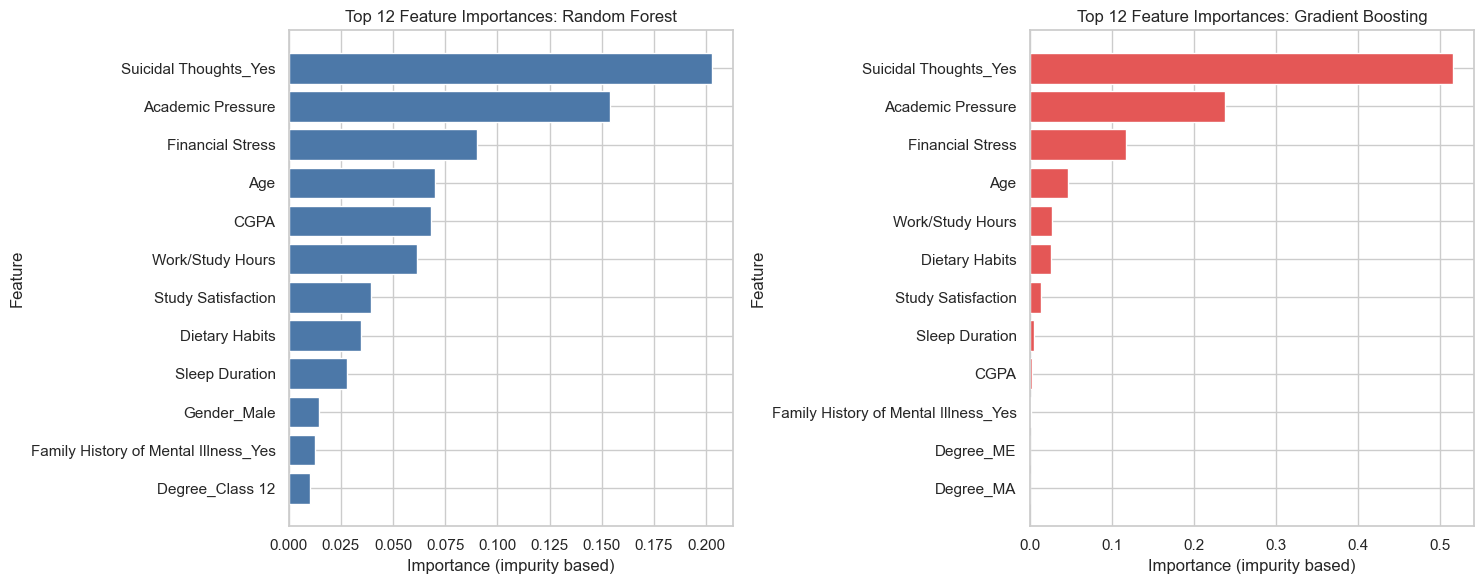

In [63]:
random_forest_importance = pd.Series(trained_pipelines["Random Forest"].named_steps["model"].feature_importances_,
                                     index=feature_names)
gradient_boosting_importance = pd.Series(trained_pipelines["Gradient Boosting"].named_steps["model"].feature_importances_,
                                         index=feature_names)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for axis, importance, title, colour in [
        (axes[0], random_forest_importance, "Random Forest", colour_main),
        (axes[1], gradient_boosting_importance, "Gradient Boosting", colour_depressed)]:
    top_features = importance.sort_values(ascending=False).head(12).sort_values()
    axis.barh(top_features.index, top_features.values, color=colour)
    axis.set_title(f"Top 12 Feature Importances: {title}")
    axis.set_xlabel("Importance (impurity based)")
    axis.set_ylabel("Feature")
plt.tight_layout()
plt.show()

### Observation

Both ensemble models agree on the top three features: **Suicidal Thoughts**, **Academic Pressure** and **Financial Stress**. In Gradient Boosting these three account for about 87% of the total importance (0.516, 0.238 and 0.117). Age, Work/Study Hours, Dietary Habits and Study Satisfaction come next. One difference is interesting: Random Forest ranks `CGPA` fifth (about 0.068), although EDA showed almost no relationship between CGPA and depression, and Gradient Boosting gives it almost zero. Impurity-based importance is known to favour continuous features with many different values (like CGPA), so this value is probably not a real signal. That is why we also use permutation importance in Section 10.3.

### 10.2 Logistic Regression coefficients

Positive coefficients increase the predicted probability of depression, negative ones decrease it. Because the numerical and ordinal features were standardised, their coefficients are comparable in size. One-hot columns are 0/1, so their coefficients show the effect of belonging to that category.

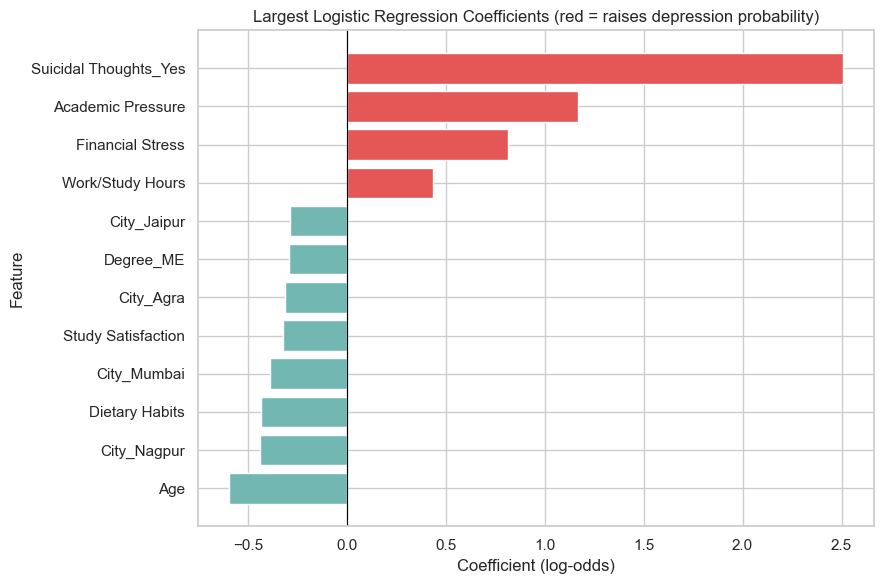

In [64]:
log_reg_coefficients = pd.Series(trained_pipelines["Logistic Regression"].named_steps["model"].coef_[0],
                                 index=feature_names)

# Take the 12 coefficients with the largest absolute size
largest_coefficients = log_reg_coefficients.reindex(
    log_reg_coefficients.abs().sort_values(ascending=False).head(12).index).sort_values()

plt.figure(figsize=(9, 6))
bar_colours = [colour_depressed if value > 0 else colour_not_depressed for value in largest_coefficients.values]
plt.barh(largest_coefficients.index, largest_coefficients.values, color=bar_colours)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Largest Logistic Regression Coefficients (red = raises depression probability)")
plt.xlabel("Coefficient (log-odds)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Observation

The largest coefficients are for **Suicidal Thoughts = Yes** (+2.51, which multiplies the odds of depression by about 12 while the other features are held constant), **Academic Pressure** (+1.17 per standard deviation), **Financial Stress** (+0.82) and **Work/Study Hours** (+0.44), which all raise the predicted risk. **Age** (-0.60), **Dietary Habits** (-0.44, better habits lower the risk) and **Study Satisfaction** (-0.32) lower it. A few single city and degree columns (Nagpur, Mumbai, Agra, Jaipur, Degree_ME) also appear, but their effect is small compared with the main features and these categories contain relatively few students. Permutation importance (next) confirms that City and Degree add almost nothing as feature groups, so these individual coefficients should not be over-interpreted.

### 10.3 Permutation importance on the test set

We shuffle each **original** feature (before preprocessing) 10 times and measure the average fall in ROC-AUC. We do this for Logistic Regression, Random Forest and Gradient Boosting. (We skip the SVM because computing it would be slow, and the other models already give a consistent picture.)

In [65]:
permutation_results = {}

for model_name in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    permutation = permutation_importance(trained_pipelines[model_name], X_test, y_test,
                                         scoring="roc_auc", n_repeats=10,
                                         random_state=RANDOM_STATE, n_jobs=2)
    permutation_results[model_name] = pd.Series(permutation.importances_mean, index=X_test.columns)

permutation_table = pd.DataFrame(permutation_results).round(4)
permutation_table = permutation_table.sort_values("Gradient Boosting", ascending=False)
permutation_table

,Logistic Regression,Random Forest,Gradient Boosting
Suicidal Thoughts,0.1091,0.1218,0.1126
Academic Pressure,0.0876,0.0847,0.0905
Financial Stress,0.0356,0.0328,0.0354
Age,0.0187,0.0138,0.0162
Dietary Habits,0.0103,0.0104,0.0105
Work/Study Hours,0.0100,0.0093,0.0099
Study Satisfaction,0.0058,0.0061,0.0055
Sleep Duration,0.0022,0.0025,0.0022
City,0.0007,0.0011,0.0004
CGPA,0.0004,0.0015,0.0004


### Plotting the permutation importance

A bar chart of the table above makes the ranking of the features easier to see. We also keep the five most important features (by Gradient Boosting) for the research summary.

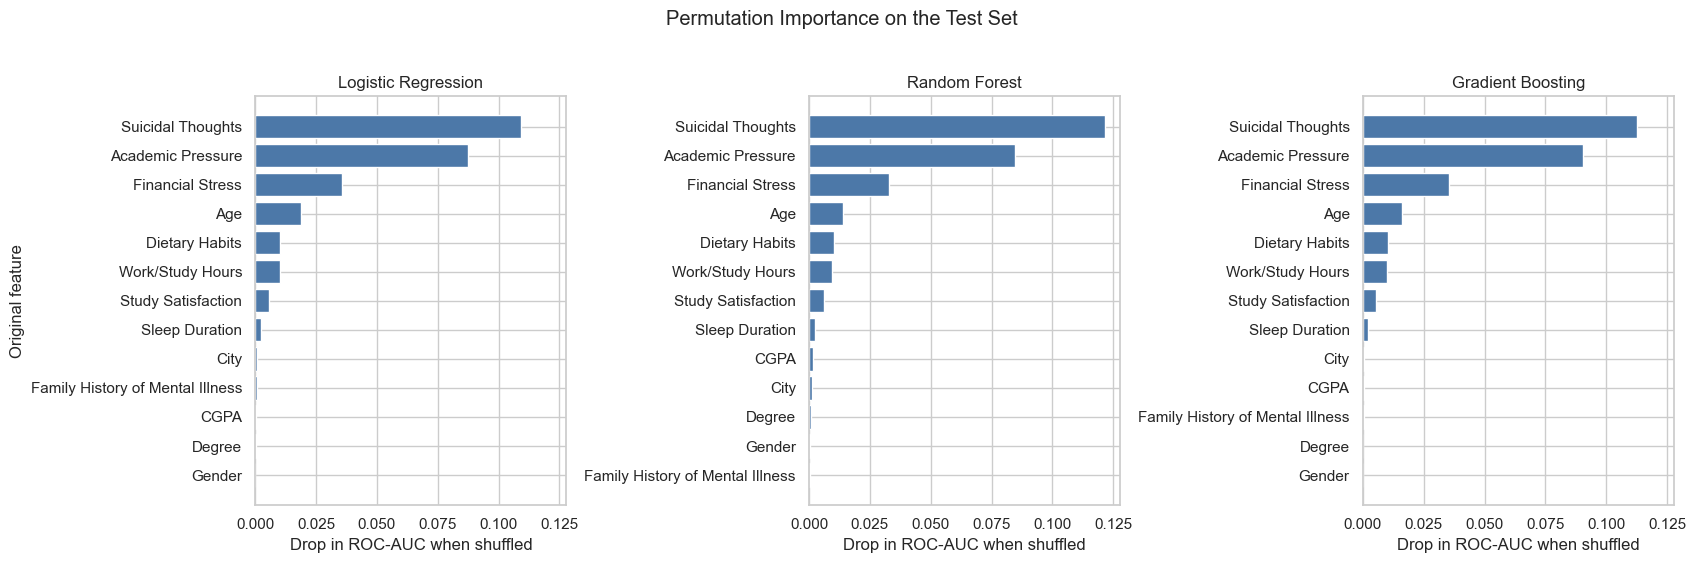

Top 5 features (Gradient Boosting permutation importance):
Suicidal Thoughts    0.1126
Academic Pressure    0.0905
Financial Stress     0.0354
Age                  0.0162
Dietary Habits       0.0105
Name: Gradient Boosting, dtype: float64


In [66]:
# Plot the permutation importance of the three models side by side
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharex=True)
for axis, model_name in zip(axes, permutation_table.columns):
    values = permutation_table[model_name].sort_values()
    axis.barh(values.index, values.values, color=colour_main)
    axis.set_title(f"{model_name}")
    axis.set_xlabel("Drop in ROC-AUC when shuffled")
axes[0].set_ylabel("Original feature")
fig.suptitle("Permutation Importance on the Test Set", y=1.02)
plt.tight_layout()
plt.show()

top_permutation_features = permutation_table["Gradient Boosting"].head(5)
print("Top 5 features (Gradient Boosting permutation importance):")
print(top_permutation_features)

### Observation

All three models give almost the same ranking. Shuffling **Suicidal Thoughts** reduces the ROC-AUC the most (about 0.11–0.12), followed by **Academic Pressure** (about 0.085–0.09), **Financial Stress** (about 0.033–0.036) and **Age** (about 0.014–0.019). Dietary Habits and Work/Study Hours (about 0.01 each), Study Satisfaction (about 0.006) and Sleep Duration (about 0.002) matter a little. City, CGPA, Family History of Mental Illness, Degree and Gender have almost no effect (below 0.002). This matches the EDA: CGPA and Gender showed almost no association, and Family History had only a small one. Reminder: these results show which features the models *use*. They do not prove that any feature causes depression, and correlated features can share importance.

# Section 11: Final Conclusion


### What was accomplished

We built a complete, reproducible machine-learning workflow on the Student Depression dataset (27,901 students, 18 original columns). We inspected the data, found and handled quality problems without deleting any student, explored the patterns with visualisations, trained seven classification models inside leakage-free pipelines, evaluated them with several metrics, cross-validated them, ran two extra experiments (without the sensitive feature, and light hyperparameter tuning) and interpreted the models with three importance techniques.

### Data-quality findings

Only 3 values were originally missing (`Financial Stress`), but there were also impossible values (ratings of 0 on a 1–5 scale, CGPA = 0), placeholder `Others` categories, 22 invalid `City` values (names and degrees entered in the city column), and three almost constant columns (`Profession`, `Work Pressure`, `Job Satisfaction`) that were dropped together with `id`. No rows were deleted.

### Patterns identified

- Depression is strongly associated with **suicidal thoughts** (about 79% vs 23%), **academic pressure** (about 19% at level 1 to 86% at level 5) and **financial stress** (about 32% to 81%).
- Moderate associations: unhealthy dietary habits, younger age, longer work/study hours and lower study satisfaction.
- Weak or no association: sleep duration (weak), family history (weak), gender and CGPA (almost none).

### Model results

| Aspect | Result |
|---|---|
| Best model (average rank of F1 and ROC-AUC) | Gradient Boosting: F1 0.870, ROC-AUC 0.920, recall 0.884 |
| Practically tied | Logistic Regression (F1 0.869, ROC-AUC 0.919), SVM and Random Forest |
| Worst | Naive Bayes (F1 0.771, accuracy 0.737) |
| Without the suicidal-thoughts feature | All models drop (F1 about 0.83 and ROC-AUC about 0.86–0.87 for the best ones), but they still work reasonably |
| Most important features | Suicidal Thoughts, Academic Pressure, Financial Stress, then Age |

Since Logistic Regression is almost as accurate as Gradient Boosting and much easier to explain, it is a good practical choice for this dataset.

### Limitations

- The dataset's source and the way `Depression` was measured are not documented, so the results may not generalise to other students.
- The data are cross-sectional, so we can find associations but not causes.
- Many features are self-reported ratings, which can be subjective.
- The strongest feature is sensitive and makes the task partly "easy", but also ethically problematic.
- Even the best models miss about 1 in 9 depressed students and flag about 1 in 5 non-depressed students at the default threshold.
- Hyperparameter tuning was light and differences between the top models are very small.
- Fairness across groups (gender, city, degree) was not tested.

### Future work

- Collect documentation about how the data and labels were created and test the models on an independent dataset.
- Study an early-warning version without the sensitive question and with more lifestyle and behavioural data.
- Tune the decision threshold to favour recall, and calibrate the predicted probabilities.
- Try SHAP explanations, broader hyperparameter searches and models designed for categorical data.
- Check fairness and bias across groups.

> **Disclaimer:** This work is an academic research project. The models are not clinical diagnostic tools and must not be used to diagnose, screen or make decisions about any real person. Anyone experiencing depression or thoughts of self-harm should contact a qualified mental-health professional or a local helpline.

# Section 12: Research Summary Generation

The code below builds `research_summary.md` automatically from the variables and tables created in this notebook. All numbers in the file come directly from this run, so the summary stays consistent with the notebook. We only include information that is real: **no references or dataset sources are invented**.

In [67]:
def dataframe_to_markdown(frame):
    # Converts a DataFrame to a Markdown table (no extra library needed)
    header = "| " + " | ".join(str(column) for column in frame.columns) + " |"
    separator = "| " + " | ".join(["---"] * len(frame.columns)) + " |"
    rows = ["| " + " | ".join(str(value) for value in row) + " |" for row in frame.itertuples(index=False)]
    return "\n".join([header, separator] + rows)


# Values used in the text
depression_rate_overall = df["Depression"].mean() * 100
rate_with_thoughts = df_clean.loc[df_clean["Suicidal Thoughts"] == "Yes", "Depression"].mean() * 100
rate_without_thoughts = df_clean.loc[df_clean["Suicidal Thoughts"] == "No", "Depression"].mean() * 100
rate_pressure_1 = df_clean.loc[df_clean["Academic Pressure"] == 1, "Depression"].mean() * 100
rate_pressure_5 = df_clean.loc[df_clean["Academic Pressure"] == 5, "Depression"].mean() * 100
rate_stress_1 = df_clean.loc[df_clean["Financial Stress"] == 1, "Depression"].mean() * 100
rate_stress_5 = df_clean.loc[df_clean["Financial Stress"] == 5, "Depression"].mean() * 100

best_row = final_comparison[final_comparison["Model"] == best_model_name].iloc[0]
# Best model without the sensitive feature, chosen with the same rule (average rank of F1 and ROC-AUC)
experiment_ranked = experiment_table.copy()
experiment_ranked["Average Rank"] = (experiment_ranked["F1-Score"].rank(ascending=False)
                                     + experiment_ranked["ROC-AUC"].rank(ascending=False)) / 2
best_without_row = experiment_ranked.sort_values("Average Rank").iloc[0]
same_model_without = experiment_table[experiment_table["Model"] == best_model_name].iloc[0]

hyperparameter_lines = []
for model_name, (estimator, needs_scaling) in model_settings.items():
    shown_parameters = {key: value for key, value in estimator.get_params().items()
                        if key in ["C", "kernel", "gamma", "max_iter", "n_neighbors", "n_estimators",
                                   "learning_rate", "max_depth", "min_samples_leaf", "random_state", "var_smoothing"]}
    hyperparameter_lines.append(f"- **{model_name}** (scaled features: {needs_scaling}): {shown_parameters}")

tuned_parameter_lines = [f"  - **{name}**: {parameters}" for name, parameters in best_parameters.items()]
decision_lines = [f"- {decision}" for decision in preprocessing_decisions]
top_feature_lines = [f"  {rank}. {name} (mean ROC-AUC drop {value:.4f})"
                     for rank, (name, value) in enumerate(top_permutation_features.items(), start=1)]

print("Values prepared for the research summary.")

Values prepared for the research summary.


### Writing the summary file

Now we use the prepared values to write the full summary text (research problem, objectives, dataset, methodology, algorithms, setup, metrics, findings, limitations and future scope) into `research_summary.md`.

In [68]:
summary_text = f'''# Research Summary: Student Depression Analysis and Prediction Using Machine Learning Techniques

*Generated automatically by `Student_Depression_ML_Analysis.ipynb`. All numbers come from the executed notebook (random_state = 42).*

## 1. Research Problem

Can the academic, lifestyle and personal information of a student be used to predict whether the student belongs to the depressed class of the dataset (`Depression = 1`), and which factors are most associated with that prediction?

## 2. Project Objectives

1. Inspect and clean the dataset, documenting data-quality problems.
2. Explore patterns between student characteristics and depression.
3. Train and compare seven classification models without data leakage.
4. Evaluate models using Accuracy, Precision, Recall, F1-Score and ROC-AUC (not accuracy alone).
5. Study the effect of the sensitive feature "Suicidal Thoughts" through a separate experiment.
6. Identify the most influential features and interpret them as associations, not causes.

## 3. Dataset Description

- **File:** `Student Depression Dataset.csv`
- **Source:** not documented in the file (no source is claimed here).
- **Dimensions:** {df.shape[0]} rows x {df.shape[1]} columns.
- **Target:** `Depression` (1 = depressed class: {depression_rate_overall:.1f}% of students, 0 = not depressed: {100 - depression_rate_overall:.1f}%).
- **Missing values:** only `Financial Stress` had missing values (3 rows). More missing values were created by converting invalid entries to NaN (see below).
- **Duplicates:** none found (also none when ignoring `id`).
- **Data-quality findings:** ratings of 0 on a 1-5 scale (Academic Pressure 9 rows, Study Satisfaction 10 rows), CGPA = 0 (9 rows), placeholder "Others" in Sleep Duration (18 rows) and Dietary Habits (12 rows), invalid city entries such as person names, degrees and numbers (22 rare City values, 26 rows in total), and nearly constant columns (Profession, Work Pressure, Job Satisfaction).
- **Label origin:** how the `Depression` label was obtained is not described in the file; this is a limitation.

## 4. Methodology

### Preprocessing decisions
{chr(10).join(decision_lines)}

### Features used ({X.shape[1]} features)
{', '.join(X.columns)}

### Train-test split
- Stratified split on the target, 80% training / 20% testing, `random_state=42`.
- Training set: {X_train.shape[0]} students. Test set: {X_test.shape[0]} students.
- Depression share: full data {y.mean():.4f}, training {y_train.mean():.4f}, test {y_test.mean():.4f}.
- Preprocessing was kept inside scikit-learn Pipelines, so imputers, encoders and scalers were fitted on training data only.

## 5. Algorithms Implemented

Logistic Regression, K-Nearest Neighbors, Decision Tree, Random Forest, Support Vector Machine (RBF kernel), Gaussian Naive Bayes, Gradient Boosting.

## 6. Experimental Setup

### Model configurations / hyperparameters (main experiment)
{chr(10).join(hyperparameter_lines)}

### Additional experiments
- 5-fold stratified cross-validation on the training set (all models).
- Separate experiment: all models retrained without the `Suicidal Thoughts` feature (same split and settings).
- Optional light hyperparameter tuning with GridSearchCV (5-fold, F1 scoring) for Logistic Regression, KNN, Decision Tree, Random Forest and Gradient Boosting. Best parameters found:
{chr(10).join(tuned_parameter_lines)}

## 7. Evaluation Metrics

Accuracy, Precision, Recall, F1-Score and ROC-AUC (positive class = depressed), confusion matrices, classification reports, ROC and Precision-Recall curves. The best model was chosen using the average rank of F1-Score and ROC-AUC, also checking Recall and cross-validation stability.

### Main results (test set, all features)

{dataframe_to_markdown(final_comparison)}

### Experiment without "Suicidal Thoughts" (test set)

{dataframe_to_markdown(experiment_table)}

### Tuned models (test set, all features)

{dataframe_to_markdown(tuned_table)}

## 8. Key Findings

- **Best model (all features):** {best_model_name} (Accuracy {best_row["Accuracy"]:.4f}, Precision {best_row["Precision"]:.4f}, Recall {best_row["Recall"]:.4f}, F1 {best_row["F1-Score"]:.4f}, ROC-AUC {best_row["ROC-AUC"]:.4f}). Several models are within a very small margin of each other (see the table and cross-validation standard deviations).
- **Best model without the sensitive feature** (same ranking rule): {best_without_row["Model"]} (F1 {best_without_row["F1-Score"]:.4f}, ROC-AUC {best_without_row["ROC-AUC"]:.4f}). For {best_model_name}, removing the feature changes F1 from {best_row["F1-Score"]:.4f} to {same_model_without["F1-Score"]:.4f} and ROC-AUC from {best_row["ROC-AUC"]:.4f} to {same_model_without["ROC-AUC"]:.4f}. All seven models got worse without it.
- **EDA patterns:** depression rate was {rate_with_thoughts:.1f}% for students reporting suicidal thoughts vs {rate_without_thoughts:.1f}% for those who did not; {rate_pressure_1:.1f}% at Academic Pressure 1 vs {rate_pressure_5:.1f}% at level 5; {rate_stress_1:.1f}% at Financial Stress 1 vs {rate_stress_5:.1f}% at level 5. Gender and CGPA showed almost no association.
- **Top features by permutation importance (Gradient Boosting, ROC-AUC drop):**
{chr(10).join(top_feature_lines)}
- Feature importance describes what the models use for prediction; it does **not** prove causation.

## 9. Limitations

- The origin of the dataset and the way the `Depression` label was collected are not documented, so generalisation to other student populations is unknown.
- The data are cross-sectional: associations only, no causal conclusions.
- Several features are self-reported ratings, which can be subjective.
- Rare and invalid values (for example in City) suggest some entries were mistyped or shifted; they were grouped or imputed rather than corrected.
- The strongest predictor (Suicidal Thoughts) is a sensitive feature and limits the model's value as an early-warning tool; it also raises ethical concerns.
- Defaults were used for most models; tuning was light. Differences between the top models are small.
- GaussianNB is not a natural fit for mostly 0/1 encoded features.
- The model is an academic research tool and must **not** be used as a clinical diagnostic system.

## 10. Future Scope

- Obtain documentation about data collection and label definition; validate on an independent dataset.
- Explore models and features built for early warning without the sensitive question.
- Try probability calibration and threshold tuning that favours Recall.
- Use SHAP or similar explanation tools and broader hyperparameter search.
- Compare with models better suited to categorical data and test fairness across groups (for example gender, city, degree).
'''

with open("research_summary.md", "w", encoding="utf-8") as summary_file:
    summary_file.write(summary_text)

print("research_summary.md written:", len(summary_text), "characters")

research_summary.md written: 10199 characters


### Observation

`research_summary.md` has been created in the notebook folder. Together with `model_comparison.csv`, it contains everything needed to start writing the research paper: dataset description, preprocessing choices, split details, model settings, results, findings, limitations and future scope.